# Notebook to simulate and tune 4 qubit quantum chip

In [1]:
from qiskit_metal import Dict
from qiskit_metal import Dict, view
from qiskit_metal.designs import QDesign
from qiskit_metal.analyses import LOManalysis

FOUR_QUBIT_DESIGN_DICT = Dict(
    # Define the overall dimensions of the planar silicon chip
    chip_size = Dict(
        size_x = '10mm',
        size_y = '10mm',
        size_z = '-280um',
        centre_x = '4mm',
        centre_y = '5mm'
    ),

    # Define standard Coplanar Waveguide (CPW) parameters used across the chip
    cpw_dims = Dict(
        width = '10 um',
        gap = '6 um'
    ),

    

    # Substrate and metal film thickness for EM simulations (Ansys Q3D/HFSS)
    physical_params = Dict(
        substrate_thickness = 280e-6,
        film_thickness = 200e-9
    ),

    # Locations and orientations of the 4 wirebond launchpads for I/O
    launchpad_options = Dict(
        p_0 = Dict(pos_x='25um' , pos_y='8500um', orientation='-90', lead_length='50 um', pad_width='80 um', pad_height='80 um'),
        p_1 = Dict(pos_x='7250um', pos_y='8500um', orientation='-90', lead_length='50 um', pad_width='80 um', pad_height='80 um'),
        p_2 = Dict(pos_x='25um' , pos_y='2000um' , orientation='90', lead_length='50 um', pad_width='80 um', pad_height='80 um'),
        p_3 = Dict(pos_x='7250um', pos_y='2000um' , orientation='90', lead_length='50 um', pad_width='80 um', pad_height='80 um')
    ),


    cpw_default_options = Dict(chip='main', hfss_wire_bonds=True),


    feedline_connections = [Dict(start_pin=Dict(component='p_0', pin='tie'), end_pin=Dict(component='ctl_0', pin='prime_end')), 
                            
                            Dict(start_pin=Dict(component='ctl_0', pin='prime_start'), end_pin=Dict(component='ctl_2', pin='prime_end')),
                            
                            Dict(start_pin=Dict(component='ctl_2', pin='prime_start'), end_pin=Dict(component='p_2', pin='tie')),
                            
                            Dict(start_pin=Dict(component='p_1', pin='tie'), end_pin=Dict(component='ctl_1', pin='prime_start')), 
                            
                            Dict(start_pin=Dict(component='ctl_1', pin='prime_end'), end_pin=Dict(component='ctl_3', pin='prime_start')),
                            
                            Dict(start_pin=Dict(component='ctl_3', pin='prime_end'), end_pin=Dict(component='p_3', pin='tie'))

    ],


    # Locations, orientations, and GDS generation names for the 4 Transmon qubits
    qubit_options = Dict(
        q_0 = Dict(pos_x='2250um', pos_y='6500um', orientation='0', gds_cell_name='Chip0725_auto', pad_width= '450 um', pad_height= "100 um", pad_gap = '20 um'),#, pocket_width='1100 um', pocket_height='1100 um'),
        q_1 = Dict(pos_x='5250um', pos_y='6500um', orientation='0', gds_cell_name='Chip0726_auto', pad_width= '450 um', pad_height= "70 um" , pad_gap = '20 um'), #, pocket_width='1100 um', pocket_height='1100 um'),
        q_2 = Dict(pos_x='2250um', pos_y='3500um', orientation='0', gds_cell_name='Chip0727_auto', pad_width= '450 um', pad_height= "90 um" , pad_gap = '20 um'), #, pocket_width='1100 um', pocket_height='1100 um'),
        q_3 = Dict(pos_x='5250um', pos_y='3500um', orientation='0', gds_cell_name='Chip0728_auto', pad_width= '450 um', pad_height= "80 um" , pad_gap = '20 um')  #, pocket_width='1100 um', pocket_height='1100 um')
    ),

    # Default geometry parameters for the TransmonPocket6 components, including coupling pads
    transmon_defaults = Dict(
        connection_pads=dict(
            resonator_pad = dict(pad_width='70um', cpw_extend='150um', pad_gap='30um'),
            coupler_short_pad = dict(pad_width='70um', cpw_extend='150um', pad_gap='30um'),
            coupler_long_pad = dict(pad_width='70um', cpw_extend='150um', pad_gap='30um')
        )
    ),

    # Explicitly defining the pad placement (Width/Height directional vectors) for each qubit
    # to ensure routing doesn't cross over itself
    qubit_pad_placements = Dict(
        q_0 = Dict(resonator_pad=Dict(loc_W=-1, loc_H=+1), coupler_short_pad=Dict(loc_W=+1, loc_H=+1), coupler_long_pad=Dict(loc_W=0, loc_H=-1)),
        q_1 = Dict(resonator_pad=Dict(loc_W=+1, loc_H=+1), coupler_short_pad=Dict(loc_W=-1, loc_H=+1), coupler_long_pad=Dict(loc_W=0, loc_H=-1)),
        q_2 = Dict(resonator_pad=Dict(loc_W=-1, loc_H=-1), coupler_short_pad=Dict(loc_W=+1, loc_H=-1), coupler_long_pad=Dict(loc_W=0, loc_H=+1)),
        q_3 = Dict(resonator_pad=Dict(loc_W=+1, loc_H=-1), coupler_short_pad=Dict(loc_W=-1, loc_H=-1), coupler_long_pad=Dict(loc_W=0, loc_H=+1)),
    ),

    # Target qubit frequencies 
    qubit_frequencies_hz = Dict(
        q_0 = 5.2,
        q_1 = 5.5, 
        q_2 = 6.1, 
        q_3 = 5.8
    ),

    # Target bare frequencies for the readout resonators
    resonator_frequencies_ghz = Dict(
        q_0 = 6.9,
        q_1 = 6.7,
        q_2 = 7.1,
        q_3 = 7.3
    ),

    # Meander routing configuration for readout resonators (lead lengths, fillet radii, asymmetry)
    resonator_meander_params = Dict(
        q_0 = Dict(fillet='70um', meander=Dict(spacing = '150um', asymmetry = '50um'), lead=Dict(start_straight='100um', end_straight='0um')),
        q_1 = Dict(fillet='70um', meander=Dict(spacing = '150um', asymmetry = '300um'), lead=Dict(start_straight='200um', end_straight='0um')),
        q_2 = Dict(fillet='70um', meander=Dict(spacing = '150um', asymmetry = '300um'), lead=Dict(start_straight='100um', end_straight='0um')),
        q_3 = Dict(fillet='70um', meander=Dict(spacing = '150um', asymmetry = '-400um'), lead=Dict(start_straight='200um', end_straight='0um'))
    ),

    # Defined total lengths for CPW bus couplers between qubits
    coupler_frequencies_ghz = Dict(
        c_q0_q1 = 6.0,
        c_q0_q2 = 6.5,
        c_q1_q3 = 6.5,
        c_q2_q3 = 6.7
    ),

    # Meander routing configuration for inter-qubit CPW couplers
    coupler_meander_params = Dict(
        c_q0_q1 = Dict(fillet='70um', meander=Dict(spacing = '150um', asymmetry = '300um'), lead=Dict(start_straight='100um', end_straight='100um')),
        c_q0_q2 = Dict(fillet='70um', meander=Dict(spacing = '150um', asymmetry = '400um'), lead=Dict(start_straight='200um', end_straight='200um')),
        c_q1_q3 = Dict(fillet='70um', meander=Dict(spacing = '200um', asymmetry = '-250um'), lead=Dict(start_straight='100um', end_straight='100um')),
        c_q2_q3 = Dict(fillet='70um', meander=Dict(spacing = '150um', asymmetry = '-200um'), lead=Dict(start_straight='100um', end_straight='100um'))
        ),

    
    readout_map = [Dict(start_pin= Dict(component='ctl_0', pin='second_end'), end_pin=Dict(component='q_0', pin='resonator_pad')), 
                   Dict(start_pin= Dict(component='ctl_1', pin='second_end'), end_pin=Dict(component='q_1', pin='resonator_pad')), 
                   Dict(start_pin= Dict(component='ctl_2', pin='second_end'), end_pin=Dict(component='q_2', pin='resonator_pad')), 
                   Dict(start_pin= Dict(component='ctl_3', pin='second_end'), end_pin=Dict(component='q_3', pin='resonator_pad')), 
                   ],

    coupled_tline_params = Dict(
                                ctl_0= Dict(pos_x='25um'  , pos_y='7000um', open_termination=True,  orientation=90 , down_length='300um', coupling_length='500um', fillet='100um', mirror=False),
                                ctl_1= Dict(pos_x='7250um', pos_y='7000um', open_termination=True,  orientation=-90, down_length='300um', coupling_length='500um', fillet='100um', mirror=True),
                                ctl_2= Dict(pos_x='25um'  , pos_y='3000um', open_termination=True,  orientation=90 , down_length='300um', coupling_length='500um', fillet='100um', mirror=False),
                                ctl_3= Dict(pos_x='7250um', pos_y='3200um', open_termination=True,  orientation=-90, down_length='300um', coupling_length='500um', fillet='100um', mirror=True)
                                ),

    coupling_map = dict(
        c_q0_q1=('q_0', 'coupler_short_pad', 'q_1', 'coupler_short_pad'),
        c_q2_q3=('q_2', 'coupler_short_pad', 'q_3', 'coupler_short_pad'),
        c_q0_q2=('q_0', 'coupler_long_pad' , 'q_2',  'coupler_long_pad'),
        c_q1_q3=('q_1', 'coupler_long_pad' , 'q_3',  'coupler_long_pad')
    ),
    
)


from qiskit_metal import Dict
from qiskit_metal import designs
# Importing specific Qiskit Metal components for a planar superconducting quantum chip
from qiskit_metal.qlibrary.qubits.transmon_pocket_6 import TransmonPocket6
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.pathfinder import RoutePathfinder
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.framed_path import RouteFramed
from qiskit_metal.qlibrary.terminations.launchpad_wb_coupled import LaunchpadWirebondCoupled
from qiskit_metal.qlibrary.terminations.launchpad_wb_driven import LaunchpadWirebondDriven
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.toolbox_metal.parsing import parse_value

#CPW calculations
from qiskit_metal.analyses.em.cpw_calculations import guided_wavelength


def connect(design, cpw_name: str, pin1_comp_name: str, pin1_comp_pin: str, pin2_comp_name: str, pin2_comp_pin: str,
            length: str, cpw_options: Dict, asymmetry='0 um'):
    """
    Helper function to abstract the creation of a RouteMeander object connecting two pins.
    Constructs the routing pin_inputs dictionary and sets meander length/asymmetry.
    """
    myoptions = Dict(pin_inputs=Dict(start_pin=Dict(component=pin1_comp_name,pin=pin1_comp_pin),end_pin=Dict(component=pin2_comp_name,pin=pin2_comp_pin)),
        total_length=length)
    myoptions.update(cpw_options)
    myoptions.meander.asymmetry = asymmetry
    return RouteMeander(design, cpw_name, myoptions)

def cal_cpw_wavelength_dict(cpw_freq, resonator_pad, substrate_thickness, film_thickness):
    """
    Uses Qiskit Metal's built-in CPW calculators to determine the required guided wavelength 
    (lambda) for a given frequency, based on line width/gap and dielectric thicknesses.
    Returns the required lambda/4 length string needed to generate a quarter-wavelength resonator.
    """
    vars_ = Dict({'x':5.0, 'y':'5um', 'cpw_width':'10um'})
    parsed_line_width = parse_value(resonator_pad.pad_width, vars_)
    parsed_line_gap = parse_value(resonator_pad.pad_gap, vars_)


    cpw_freq = cpw_freq * (10**9) # Converting Ghz to hz
    resonator_dict = {'freq':cpw_freq}
    
    # Extract lambda, effective epsilon, and quality factor limit
    (resonator_dict['lambda'], resonator_dict['eps_eff'], resonator_dict['qf']) = guided_wavelength(
        freq=cpw_freq, 
        line_width=parsed_line_width, 
        line_gap=parsed_line_gap, 
        substrate_thickness=substrate_thickness, 
        film_thickness=film_thickness
    )
    
    # Format and store the lambda/4 length for direct insertion into RouteMeander
    resonator_dict['lambda'] = round(1000*resonator_dict['lambda'], 3)
    resonator_dict['lambda4_str'] = str(resonator_dict['lambda']/4) + ' mm'
    return resonator_dict



def create_design(DESIGN_DICT):
    # Create a planar design object and instantiate the GUI
    design = designs.DesignPlanar()

    design.overwrite_enabled = True # Allows overriding components with the same name during testing

    # --- Set Global Chip Properties ---
    design.variables['cpw_width'] = DESIGN_DICT.cpw_dims.width
    design.variables['cpw_gap'] = DESIGN_DICT.cpw_dims.gap
    design.chips['main']['size']['size_x'] = DESIGN_DICT.chip_size.size_x
    design.chips['main']['size']['size_y'] = DESIGN_DICT.chip_size.size_y
    design.chips['main']['size']['center_x'] = DESIGN_DICT.chip_size.centre_x
    design.chips['main']['size']['center_y'] = DESIGN_DICT.chip_size.centre_y
    design.chips['main']['size']['size_z'] = DESIGN_DICT.chip_size.size_z
    # --- Loop-Based Component Generation ---
    print("Generating Launchpads...")
    for name, options in DESIGN_DICT.launchpad_options.items():
        LaunchpadWirebondDriven(design, name, options=options)

    print("Generating CoupledLineTee")

    for ctl_name in DESIGN_DICT.coupled_tline_params.keys():

        CoupledLineTee(design, ctl_name, options=DESIGN_DICT.coupled_tline_params[ctl_name])

        
    print("Connecting...")
    
    for pin_input_connection in DESIGN_DICT.feedline_connections:

        fline_options = dict(pin_inputs=pin_input_connection)

        # fline_options.update(DESIGN_DICT.cpw_default_options)
        RouteFramed(design, 'cpw_'+pin_input_connection.start_pin.component+pin_input_connection.end_pin.component, options=fline_options)


    

    print("Generating Qubits...")
    for name, options in DESIGN_DICT.qubit_options.items():
        full_opts = DESIGN_DICT.transmon_defaults.copy()
        
        # Apply specific width/height mapping to ensure pins align correctly for routing
        for pad_name, placement in DESIGN_DICT.qubit_pad_placements[name].items():
            full_opts.connection_pads[pad_name].update(placement)
            
        TransmonPocket6(design, name, options=dict(**options, **full_opts))

    print("Generating Readout Resonators...")
    
    for entry in DESIGN_DICT.readout_map:
        # Fetch parameters to dynamically compute lambda/4 length for exact frequency
        q_name = entry.end_pin.component
        resonator_pad = design.components[q_name].options.connection_pads.resonator_pad

        resonator_dict = cal_cpw_wavelength_dict(DESIGN_DICT.resonator_frequencies_ghz[q_name], resonator_pad, **DESIGN_DICT.physical_params)
        meander_params = DESIGN_DICT.resonator_meander_params[q_name]
        
        cpw_options = DESIGN_DICT.cpw_default_options

        cpw_options.update(fillet=meander_params.fillet,  meander=meander_params.meander, lead=meander_params.lead)

        cpw_options.update(total_length=resonator_dict['lambda4_str'], pin_inputs=Dict(start_pin=entry.start_pin, end_pin=entry.end_pin))
        
        # Route the resonator using the dynamically calculated quarter-wavelength string
        RouteMeander(design, f'{q_name}_resonator', options=cpw_options)
        

    print("Generating Couplers...")
    
    for coup_name in DESIGN_DICT.coupling_map.keys():
        meander_params = DESIGN_DICT.coupler_meander_params[coup_name]
        
        q1_name = DESIGN_DICT.coupling_map[coup_name][0]
        q1_pad  = DESIGN_DICT.coupling_map[coup_name][1]
        q2_name = DESIGN_DICT.coupling_map[coup_name][2]
        q2_pad  = DESIGN_DICT.coupling_map[coup_name][3]

        coupler_pad = design.components[DESIGN_DICT.coupling_map[coup_name][0]].options.connection_pads[q1_pad]

        coupler_dict = cal_cpw_wavelength_dict(DESIGN_DICT.coupler_frequencies_ghz[coup_name], coupler_pad, **DESIGN_DICT.physical_params)

        cpw_options = DESIGN_DICT.cpw_default_options

        cpw_options.update(fillet=meander_params.fillet, meander=meander_params.meander, lead=meander_params.lead)

        cpw_options.update(total_length=coupler_dict['lambda4_str'], pin_inputs=Dict(start_pin=Dict(component=q1_name, pin=q1_pad), end_pin=Dict(component=q2_name, pin=q2_pad)))
        
        # Route the coupler using the dynamically calculated quarter-wavelength string
        RouteMeander(design, coup_name, options=cpw_options)

    return design








design = create_design(FOUR_QUBIT_DESIGN_DICT)

Generating Launchpads...
Generating CoupledLineTee
Connecting...
Generating Qubits...
Generating Readout Resonators...
Generating Couplers...


In [2]:
design.chips

{'main': {'material': 'silicon',
  'layer_start': '0',
  'layer_end': '2048',
  'size': {'center_x': '4mm',
   'center_y': '5mm',
   'center_z': '0.0mm',
   'size_x': '10mm',
   'size_y': '10mm',
   'size_z': '-280um',
   'sample_holder_top': '890um',
   'sample_holder_bottom': '1650um'}}}

## Acutal Setup and Analysis

## Q0

In [3]:


def print_qubit_properties(design, qubit_name):
    design.components[qubit_name].options.pad_width = '500 um'
    design.components[qubit_name].options.pad_height = '100 um'
    design.components[qubit_name].options.pad_gap = '30 um'
    # print(design.components[qubit_name].options.connection_pads.resonator_pad.pad_gap)
    design.components[qubit_name].options.connection_pads.resonator_pad.pad_gap = '40 um'
    design.components[qubit_name].options.connection_pads.coupler_short_pad.pad_gap = '30 um'
    design.components[qubit_name].options.connection_pads.coupler_long_pad.pad_gap = '35 um'


    design.components[qubit_name].options.connection_pads.resonator_pad.pad_width = '70 um'
    design.components[qubit_name].options.connection_pads.coupler_short_pad.pad_width = '70 um'
    design.components[qubit_name].options.connection_pads.coupler_long_pad.pad_width = '70 um'

    print("-"*50)
    print(f"Capacitive tuninig {qubit_name}")
    print("-"*50)
    print(f"pad_width = {design.components[qubit_name].options.pad_width}\npad_height = {design.components[qubit_name].options.pad_height}\npad_gap = {design.components[qubit_name].options.pad_gap}")
    print("-"*50)

    for pin in design.components[qubit_name].pin_names:
        print(f"For pin {pin}")
        print(f"    pad_width = {design.components[qubit_name].options.connection_pads[pin].pad_width}")
        print(f"    pad_height = {design.components[qubit_name].options.connection_pads[pin].pad_height}")
        print(f"    pad_gap = {design.components[qubit_name].options.connection_pads[pin].pad_gap}")
        print("-"*50)

    design.rebuild()
    
    return None

def get_side_frequencies_for_qubit(qubit_name, DESIGN_DICT):

    qubit = qubit_name.replace('_', '')

    coupler_list = [freq for name, freq in DESIGN_DICT.coupler_frequencies_ghz.items() if qubit in name]

    print(coupler_list)

    return coupler_list

In [4]:
qubit_name = 'q_0'
print(print_qubit_properties(design, qubit_name='q_0'))

--------------------------------------------------
Capacitive tuninig q_0
--------------------------------------------------
pad_width = 500 um
pad_height = 100 um
pad_gap = 30 um
--------------------------------------------------
For pin resonator_pad
    pad_width = 70 um
    pad_height = 30um
    pad_gap = 40 um
--------------------------------------------------
For pin coupler_short_pad
    pad_width = 70 um
    pad_height = 30um
    pad_gap = 30 um
--------------------------------------------------
For pin coupler_long_pad
    pad_width = 70 um
    pad_height = 30um
    pad_gap = 35 um
--------------------------------------------------


None


In [5]:
from qiskit_metal.analyses import LOManalysis

lom = LOManalysis(design, 'q3d')

In [6]:


sweep_setup = Dict(design = design,
                        # Only simulate q0 and define its open terminations to extract exact capacitance matrix
                        run_args_dict = Dict(components=[design.components[qubit_name].name] , open_terminations=[(design.components[qubit_name].name, pad) for pad in design.components[qubit_name].pins.keys()]),
                        # LOM physics constraints (Josephson Junction Inductance & Capacitance)
                        lom_setup = Dict(junctions=Dict(Lj=11.5, Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz[qubit_name], freq_bus=get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT)),
                        # Ansys Q3D Iterative solver properties
                        lom_sim_setup = Dict(name = f'{qubit_name}_setup', 
                                             reuse_selected_design = True, 
                                             reuse_setup = True,
                                             freq_ghz = FOUR_QUBIT_DESIGN_DICT.qubit_frequencies_hz[qubit_name],
                                             save_fields = True, 
                                             enabled = True, 
                                             max_passes = 35, 
                                             min_passes = 2, 
                                             min_converged_passes = 3, 
                                             percent_error = 0.05, 
                                             percent_refinement = 30, 
                                             auto_increase_solution_order = True, 
                                             solution_order = 'Highest', 
                                             solver_type = 'Iterative',
                                             ))



print(sweep_setup)

lom.sim.design.rebuild()

print(print_qubit_properties(design, qubit_name='q_0'))

lom.setup = sweep_setup.lom_setup
lom.sim.setup = sweep_setup.lom_sim_setup

lom.sim.run(name=qubit_name+'_capacitive', components = sweep_setup.run_args_dict.components, open_terminations = sweep_setup.run_args_dict.open_terminations, box_plus_buffer=True)
lom.run_lom()

[6.0, 6.5]
{'design': <qiskit_metal.designs.design_planar.DesignPlanar object at 0x0000016EA4231D50>, 'run_args_dict': {'components': ['q_0'], 'open_terminations': [('q_0', 'resonator_pad'), ('q_0', 'coupler_short_pad'), ('q_0', 'coupler_long_pad')]}, 'lom_setup': {'junctions': {'Lj': 11.5, 'Cj': 2}, 'freq_readout': 6.9, 'freq_bus': [6.0, 6.5]}, 'lom_sim_setup': {'name': 'q_0_setup', 'reuse_selected_design': True, 'reuse_setup': True, 'freq_ghz': 5.2, 'save_fields': True, 'enabled': True, 'max_passes': 35, 'min_passes': 2, 'min_converged_passes': 3, 'percent_error': 0.05, 'percent_refinement': 30, 'auto_increase_solution_order': True, 'solution_order': 'Highest', 'solver_type': 'Iterative'}}
--------------------------------------------------
Capacitive tuninig q_0
--------------------------------------------------
pad_width = 500 um
pad_height = 100 um
pad_gap = 30 um
--------------------------------------------------
For pin resonator_pad
    pad_width = 70 um
    pad_height = 30um
  

INFO 01:45AM [connect_project]: Connecting to Ansys Desktop API...
INFO 01:45AM [load_ansys_project]: 	Opened Ansys App
INFO 01:45AM [load_ansys_project]: 	Opened Ansys Desktop v2025.1.4
INFO 01:45AM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Bowtie
INFO 01:45AM [connect_design]: No active design found (or error getting active design).
INFO 01:45AM [connect]: 	 Connected to project "Bowtie". No design detected


None


INFO 01:45AM [connect_design]: 	Opened active design
	Design:    q_0_capacitive_q3d [Solution type: Q3D]
WARNING 01:45AM [connect_setup]: 	No design setup detected.
WARNING 01:45AM [connect_setup]: 	Creating Q3D default setup.
INFO 01:45AM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 01:45AM [get_setup]: 	Opened setup `q_0_setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 01:45AM [analyze]: Analyzing setup q_0_setup
INFO 02:11AM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmpmqdwo0sy.txt, C, , q_0_setup:LastAdaptive, "Original", "ohm", "nH", "fF", "mSie", 5200000000, Maxwell, 1, False
INFO 02:11AM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmphvug576z.txt, C, , q_0_setup:AdaptivePass, "Original", "ohm", "nH", "fF", "mSie", 5200000000, Maxwell, 1, False
INFO 02:11AM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmpdj9oejrm.txt, C, , q_0_setup:AdaptivePass, "Original",

[3, 4] [5 0 1]
Predicted Values

Transmon Properties
f_Q 5.198027 [GHz]
EC 263.867231 [MHz]
EJ 14.202584 [GHz]
alpha -301.166708 [MHz]
dispersion 5.407886 [KHz]
Lq 11.500000 [nH]
Cq 73.408994 [fF]
T1 352.786089 [us]

**Coupling Properties**

tCqbus1 -2.656408 [fF]
gbus1_in_MHz -36.307899 [MHz]
χ_bus1 -0.238467 [MHz]
1/T1bus1 231.875026 [Hz]
T1bus1 686.382428 [us]

tCqbus2 3.894832 [fF]
gbus2_in_MHz 46.268961 [MHz]
χ_bus2 -1.468127 [MHz]
1/T1bus2 172.133471 [Hz]
T1bus2 924.601949 [us]

tCqbus3 -3.064136 [fF]
gbus3_in_MHz -39.448665 [MHz]
χ_bus3 -0.456115 [MHz]
1/T1bus3 47.128744 [Hz]
T1bus3 3377.024892 [us]
Bus-Bus Couplings
gbus1_2 1.788784 [MHz]
gbus1_3 1.564925 [MHz]
gbus2_3 1.862902 [MHz]


,fQ,EC,EJ,alpha,dispersion,gbus,chi_in_MHz,χr MHz,gr MHz
1,5.601589,309.352045,14.202584,-358.070279,25.010978,"[-34.62190291984902, 47.90995488405509, -42.59...","[-0.40477254148940894, -5.466666238899318, -1....",0.404773,34.621903
2,5.538687,301.991229,14.202584,-348.76655,19.996143,"[-36.62791644898477, 46.30009565268613, -37.54...","[-0.4082128133847065, -4.012924541186444, -0.7...",0.408213,36.627916
3,5.430133,289.525288,14.202584,-333.0942,13.422646,"[-34.48735062301854, 45.88218453320238, -38.24...","[-0.3043434629877452, -2.7365352598456263, -0....",0.304343,34.487351
4,5.364995,282.188293,14.202584,-323.919196,10.484397,"[-34.77581179344436, 46.37948765752214, -38.04...","[-0.27991734479011315, -2.299637994371974, -0....",0.279917,34.775812
5,5.310459,276.127527,14.202584,-316.367506,8.48503,"[-35.329957652906266, 45.878237037051484, -38....","[-0.26613391151957216, -1.9307766860239204, -0...",0.266134,35.329958
6,5.280258,272.803294,14.202584,-312.236018,7.532465,"[-35.33370234228732, 45.59925457833298, -38.58...","[-0.2545331852598412, -1.758654639700232, -0.5...",0.254533,35.333702
7,5.258728,270.447385,14.202584,-309.312497,6.913541,"[-35.749164202370885, 45.78193364324315, -38.7...","[-0.25244032053832755, -1.6754914774808536, -0...",0.252440,35.749164
8,5.240822,268.496734,14.202584,-306.894693,6.434183,"[-35.715358136649776, 45.85704492511973, -38.7...","[-0.24546346346691825, -1.6052809454207562, -0...",0.245463,35.715358
9,5.230466,267.372283,14.202584,-305.502113,6.170875,"[-35.792108441058105, 45.76020590656884, -38.8...","[-0.24283916954896656, -1.556996348853149, -0....",0.242839,35.792108
10,5.224869,266.765684,14.202584,-304.751219,6.032661,"[-35.93766492324996, 45.81564381495158, -39.02...","[-0.24284139238123892, -1.5388887887130558, -0...",0.242841,35.937665


In [7]:
import numpy as np
FOUR_QUBIT_DESIGN_DICT.simulations.capacitive.q_0 = Dict(lumped_oscillator = lom.lumped_oscillator, cap_matrix = lom.sim.capacitance_matrix)
FOUR_QUBIT_DESIGN_DICT.simulations.capacitive

{'q_0': {'lumped_oscillator': {'fQ': 5.198027045008854,
   'EC': 263.8672313949839,
   'EJ': 14.202583590033388,
   'alpha': -301.1667076080627,
   'dispersion': 5.4078859558105465,
   'gbus': array([-36.30789889,  46.26896053, -39.44866496]),
   'chi_in_MHz': array([-0.23846675, -1.46812679, -0.45611548])},
  'cap_matrix':                                      coupler_long_pad_connector_pad_q_0  \
  coupler_long_pad_connector_pad_q_0                             50.39195   
  coupler_short_pad_connector_pad_q_0                            -0.08170   
  ground_main_plane                                             -39.39882   
  pad_bot_q_0                                                    -9.06706   
  pad_top_q_0                                                    -1.33219   
  resonator_pad_connector_pad_q_0                                -0.08135   
  
                                       coupler_short_pad_connector_pad_q_0  \
  coupler_long_pad_connector_pad_q_0                    

INFO 02:13AM [__init__]: Design "q_0_capacitive_q3d" info:
INFO 02:13AM [__init__]: 	# eigenmodes    0
	# variations    1
INFO 02:13AM [hfss_report_full_convergence]: Creating report for variation 0


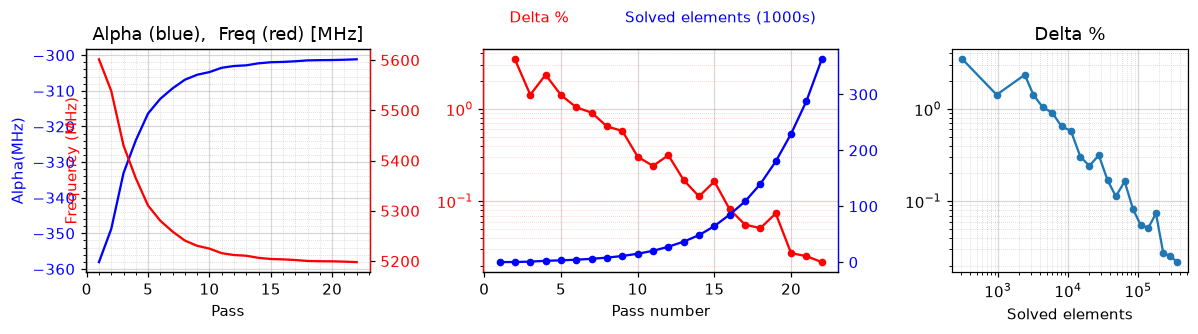

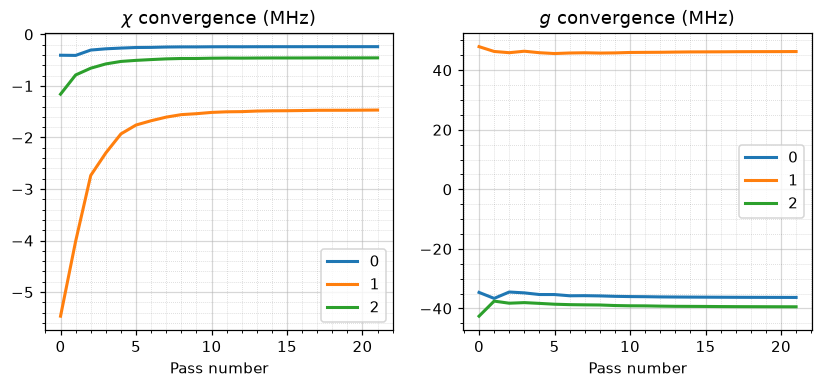

In [8]:
lom.plot_convergence()
lom.plot_convergence_chi()

In [9]:
lom.sim.close()


## Q1

In [8]:
qubit_name = 'q_1'

def print_qubit_properties(design, qubit_name):
    # design.components[qubit_name].options.pad_width = '500 um'
    # design.components[qubit_name].options.pad_height = '100 um'
    # design.components[qubit_name].options.pad_gap = '30 um'
    # # print(design.components[qubit_name].options.connection_pads.resonator_pad.pad_gap)
    design.components[qubit_name].options.connection_pads.resonator_pad.pad_gap = '40 um'
    design.components[qubit_name].options.connection_pads.coupler_short_pad.pad_gap = '30 um'
    design.components[qubit_name].options.connection_pads.coupler_long_pad.pad_gap = '35 um'


    # design.components[qubit_name].options.connection_pads.resonator_pad.pad_width = '70 um'
    # design.components[qubit_name].options.connection_pads.coupler_short_pad.pad_width = '70 um'
    # design.components[qubit_name].options.connection_pads.coupler_long_pad.pad_width = '70 um'

    print("-"*50)
    print(f"Capacitive tuninig {qubit_name}")
    print("-"*50)
    print(f"pad_width = {design.components[qubit_name].options.pad_width}\npad_height = {design.components[qubit_name].options.pad_height}\npad_gap = {design.components[qubit_name].options.pad_gap}")
    print("-"*50)

    for pin in design.components[qubit_name].pin_names:
        print(f"For pin {pin}")
        print(f"    pad_width = {design.components[qubit_name].options.connection_pads[pin].pad_width}")
        print(f"    pad_height = {design.components[qubit_name].options.connection_pads[pin].pad_height}")
        print(f"    pad_gap = {design.components[qubit_name].options.connection_pads[pin].pad_gap}")
        print("-"*50)

    design.rebuild()
    
    return None

def get_side_frequencies_for_qubit(qubit_name, DESIGN_DICT):

    qubit = qubit_name.replace('_', '')

    coupler_list = [freq for name, freq in DESIGN_DICT.coupler_frequencies_ghz.items() if qubit in name]

    print(coupler_list)

    return coupler_list

In [9]:
print_qubit_properties(design, qubit_name)
get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT)

--------------------------------------------------
Capacitive tuninig q_1
--------------------------------------------------
pad_width = 450 um
pad_height = 70 um
pad_gap = 20 um
--------------------------------------------------
For pin coupler_long_pad
    pad_width = 70um
    pad_height = 30um
    pad_gap = 35 um
--------------------------------------------------
For pin coupler_short_pad
    pad_width = 70um
    pad_height = 30um
    pad_gap = 30 um
--------------------------------------------------
For pin resonator_pad
    pad_width = 70um
    pad_height = 30um
    pad_gap = 40 um
--------------------------------------------------
[6.0, 6.5]


[6.0, 6.5]

In [ ]:
from qiskit_metal.analyses import LOManalysis

lom = LOManalysis(design, 'q3d')

sweep_setup = Dict(design = design,
                        # Only simulate qubit and define its open terminations to extract exact capacitance matrix
                        run_args_dict = Dict(components=[design.components[qubit_name].name] , open_terminations=[(design.components[qubit_name].name, pad) for pad in design.components[qubit_name].pins.keys()]),
                        # LOM physics constraints (Josephson Junction Inductance & Capacitance)
                        lom_setup = Dict(junctions=Dict(Lj=12, Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz[qubit_name], freq_bus=get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT)),
                        # Ansys Q3D Iterative solver properties
                        lom_sim_setup = Dict(name = f'{qubit_name}_setup', 
                                             reuse_selected_design = True, 
                                             reuse_setup = True,
                                             freq_ghz = FOUR_QUBIT_DESIGN_DICT.qubit_frequencies_hz[qubit_name],
                                             save_fields = True, 
                                             enabled = True, 
                                             max_passes = 35, 
                                             min_passes = 2, 
                                             min_converged_passes = 3, 
                                             percent_error = 0.05, 
                                             percent_refinement = 30, 
                                             auto_increase_solution_order = True, 
                                             solution_order = 'Highest', 
                                             solver_type = 'Iterative',
                                             ))



print(sweep_setup)

lom.sim.design.rebuild()

print(print_qubit_properties(design, qubit_name))

lom.setup = sweep_setup.lom_setup
lom.sim.setup = sweep_setup.lom_sim_setup

lom.sim.run(name=qubit_name+'_capacitive', components = sweep_setup.run_args_dict.components, open_terminations = sweep_setup.run_args_dict.open_terminations, box_plus_buffer=True)
lom.run_lom()

[6.0, 6.5]
{'design': <qiskit_metal.designs.design_planar.DesignPlanar object at 0x0000025F5EC96550>, 'run_args_dict': {'components': ['q_1'], 'open_terminations': [('q_1', 'resonator_pad'), ('q_1', 'coupler_short_pad'), ('q_1', 'coupler_long_pad')]}, 'lom_setup': {'junctions': {'Lj': 12, 'Cj': 2}, 'freq_readout': 6.7, 'freq_bus': [6.0, 6.5]}, 'lom_sim_setup': {'name': 'q_1_setup', 'reuse_selected_design': True, 'reuse_setup': True, 'freq_ghz': 5.5, 'save_fields': True, 'enabled': True, 'max_passes': 35, 'min_passes': 2, 'min_converged_passes': 3, 'percent_error': 0.05, 'percent_refinement': 30, 'auto_increase_solution_order': True, 'solution_order': 'Highest', 'solver_type': 'Iterative'}}
--------------------------------------------------
Capacitive tuninig q_1
--------------------------------------------------
pad_width = 450 um
pad_height = 70 um
pad_gap = 20 um
--------------------------------------------------
For pin coupler_long_pad
    pad_width = 70um
    pad_height = 30um
   

INFO 12:21PM [connect_project]: Connecting to Ansys Desktop API...
INFO 12:21PM [load_ansys_project]: 	Opened Ansys App
INFO 12:21PM [load_ansys_project]: 	Opened Ansys Desktop v2025.1.4
INFO 12:21PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Qubit_design_project
INFO 12:21PM [connect_design]: 	Opened active design
	Design:    q_0_capacitive_q3d [Solution type: Q3D]
INFO 12:21PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 12:21PM [connect]: 	Connected to project "Qubit_design_project" and design "q_0_capacitive_q3d" 😀 



None


INFO 12:21PM [connect_design]: 	Opened active design
	Design:    q_1_capacitive_q3d [Solution type: Q3D]
WARNING 12:21PM [connect_setup]: 	No design setup detected.
WARNING 12:21PM [connect_setup]: 	Creating Q3D default setup.
INFO 12:21PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 12:21PM [get_setup]: 	Opened setup `q_1_setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 12:21PM [analyze]: Analyzing setup q_1_setup
INFO 12:42PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmpt4uhxan2.txt, C, , q_1_setup:LastAdaptive, "Original", "ohm", "nH", "fF", "mSie", 5500000000, Maxwell, 1, False
INFO 12:42PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmpx72iksck.txt, C, , q_1_setup:AdaptivePass, "Original", "ohm", "nH", "fF", "mSie", 5500000000, Maxwell, 1, False
INFO 12:42PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmp4pqdfccz.txt, C, , q_1_setup:AdaptivePass, "Original",

[3, 4] [5 0 1]
Predicted Values

Transmon Properties
f_Q 5.385625 [GHz]
EC 298.520881 [MHz]
EJ 13.610809 [GHz]
alpha -345.759220 [MHz]
dispersion 25.547292 [KHz]
Lq 12.000000 [nH]
Cq 64.887347 [fF]
T1 222.161037 [us]

**Coupling Properties**

tCqbus1 -2.367452 [fF]
gbus1_in_MHz -34.227157 [MHz]
χ_bus1 -0.376974 [MHz]
1/T1bus1 360.887817 [Hz]
T1bus1 441.009465 [us]

tCqbus2 3.500237 [fF]
gbus2_in_MHz 45.297401 [MHz]
χ_bus2 -2.416678 [MHz]
1/T1bus2 291.910639 [Hz]
T1bus2 545.218029 [us]

tCqbus3 -2.742756 [fF]
gbus3_in_MHz -38.463200 [MHz]
χ_bus3 -0.636198 [MHz]
1/T1bus3 63.596035 [Hz]
T1bus3 2502.592214 [us]
Bus-Bus Couplings
gbus1_2 2.500909 [MHz]
gbus1_3 2.201803 [MHz]
gbus2_3 2.655661 [MHz]


,fQ,EC,EJ,alpha,dispersion,gbus,chi_in_MHz,χr MHz,gr MHz
1,5.80415,350.410176,13.610809,-412.525328,105.044934,"[-39.504315640451054, 47.45052588466756, -33.6...","[-1.1070205930268688, -15.604564374472847, -1....",1.107021,39.504316
2,5.777931,347.018012,13.610809,-408.100299,96.731733,"[-34.86764787846002, 46.766926025169916, -38.6...","[-0.8156322367503923, -12.769770613824367, -1....",0.815632,34.867648
3,5.67943,334.444705,13.610809,-391.773007,70.475415,"[-33.432932006277625, 45.03923027568623, -37.1...","[-0.6135199635318139, -6.972474583675305, -1.0...",0.613520,33.432932
4,5.607992,325.493304,13.610809,-380.21986,55.617316,"[-33.361324903335905, 45.74564833291827, -37.2...","[-0.5322068634276986, -5.269035630679572, -0.9...",0.532207,33.361325
5,5.524641,315.225968,13.610809,-367.040178,41.861193,"[-33.52276523645808, 44.82563084370971, -37.50...","[-0.46073796317589694, -3.6949423939910795, -0...",0.460738,33.522765
6,5.502437,312.522661,13.610809,-363.582768,38.752163,"[-33.657008305374255, 44.863406690747816, -37....","[-0.44629989080169774, -3.4272265831367945, -0...",0.446300,33.657008
7,5.455597,306.863879,13.610809,-356.362486,32.861229,"[-33.767382721017256, 44.796109957715665, -37....","[-0.41363575754176257, -2.927801956633731, -0....",0.413636,33.767383
8,5.444755,305.56257,13.610809,-354.705347,31.617675,"[-33.822341160465456, 44.90812496244666, -37.9...","[-0.4072403710428481, -2.8429611117798927, -0....",0.407240,33.822341
9,5.42335,303.002601,13.610809,-351.448922,29.285406,"[-33.746516784708625, 44.64781944725643, -37.8...","[-0.39073026432556723, -2.6291789847194376, -0...",0.390730,33.746517
10,5.414542,301.952723,13.610809,-350.114776,28.371274,"[-33.92591195037269, 44.865733484109235, -38.0...","[-0.3889873100224743, -2.58449501701725, -0.65...",0.388987,33.925912


In [ ]:
lom.setup = Dict(junctions=Dict(Lj=11.5, Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz[qubit_name], freq_bus=get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT))
lom.run_lom()

[6.0, 6.5]
[3, 4] [5 0 1]
Predicted Values

Transmon Properties
f_Q 5.508728 [GHz]
EC 298.520881 [MHz]
EJ 14.202584 [GHz]
alpha -344.392990 [MHz]
dispersion 17.941726 [KHz]
Lq 11.500000 [nH]
Cq 64.887347 [fF]
T1 155.761760 [us]

**Coupling Properties**

tCqbus1 -2.367452 [fF]
gbus1_in_MHz -34.593275 [MHz]
χ_bus1 -0.456258 [MHz]
1/T1bus1 460.106225 [Hz]
T1bus1 345.909128 [us]

tCqbus2 3.500237 [fF]
gbus2_in_MHz 45.781935 [MHz]
χ_bus2 -3.527799 [MHz]
1/T1bus2 477.533116 [Hz]
T1bus2 333.285667 [us]

tCqbus3 -2.742756 [fF]
gbus3_in_MHz -38.874630 [MHz]
χ_bus3 -0.793619 [MHz]
1/T1bus3 84.145103 [Hz]
T1bus3 1891.434417 [us]
Bus-Bus Couplings
gbus1_2 2.500909 [MHz]
gbus1_3 2.201803 [MHz]
gbus2_3 2.655661 [MHz]


,fQ,EC,EJ,alpha,dispersion,gbus,chi_in_MHz,χr MHz,gr MHz
1,5.937628,350.410176,14.202584,-410.650402,76.17853,"[-39.92688179594991, 47.95809033615629, -34.01...","[-1.472536991053024, -64.03972116590045, -1.74...",1.472537,39.926882
2,5.910755,347.018012,14.202584,-406.261823,70.018161,"[-35.24061694972275, 47.26717820811672, -39.09...","[-1.0760024364131704, -41.063936016331965, -2....",1.076002,35.240617
3,5.8098,334.444705,14.202584,-390.065581,50.646538,"[-33.79055433983556, 45.52100180053543, -37.53...","[-0.7874505356362427, -14.659201149742197, -1....",0.787451,33.790554
4,5.736588,325.493304,14.202584,-378.60195,39.75446,"[-33.71818127657519, 46.23497620592286, -37.63...","[-0.6715834555678961, -9.58348819251734, -1.23...",0.671583,33.718181
5,5.651173,315.225968,14.202584,-365.521201,29.729501,"[-33.881348489907886, 45.305117557663614, -37....","[-0.5713917077797811, -6.033082523244018, -1.0...",0.571392,33.881348
6,5.62842,312.522661,14.202584,-362.089191,27.473388,"[-34.01702751782284, 45.343297481932154, -38.2...","[-0.5511422457261723, -5.472947613561491, -0.9...",0.551142,34.017028
7,5.580423,306.863879,14.202584,-354.921218,23.210138,"[-34.12858257643427, 45.27528089535248, -38.25...","[-0.5064870764324644, -4.488865610905535, -0.8...",0.506487,34.128583
8,5.569314,305.56257,14.202584,-353.275945,22.312308,"[-34.18412889029804, 45.38849409195544, -38.34...","[-0.4977191269606371, -4.322239844999931, -0.8...",0.497719,34.184129
9,5.547382,303.002601,14.202584,-350.042688,20.630629,"[-34.10749344328388, 45.125404164504786, -38.2...","[-0.4758124406755494, -3.9350230219279068, -0....",0.475812,34.107493
10,5.538356,301.952723,14.202584,-348.717977,19.972313,"[-34.28880754677134, 45.34564916432428, -38.49...","[-0.4729990793411879, -3.8445542498052983, -0....",0.472999,34.288808


In [ ]:
import numpy as np
FOUR_QUBIT_DESIGN_DICT.simulations.capacitive.q_1 = Dict(lumped_oscillator = lom.lumped_oscillator, cap_matrix = lom.sim.capacitance_matrix)
FOUR_QUBIT_DESIGN_DICT.simulations.capacitive

{'q_0': {'lumped_oscillator': {'fQ': 5.198027045008854,
   'EC': 263.8672313949839,
   'EJ': 14.202583590033388,
   'alpha': -301.1667076080627,
   'dispersion': 5.4078859558105465,
   'gbus': array([-36.30789889,  46.26896053, -39.44866496]),
   'chi_in_MHz': array([-0.23846675, -1.46812679, -0.45611548])},
  'cap_matrix':                                      coupler_long_pad_connector_pad_q_0  \
  coupler_long_pad_connector_pad_q_0                             50.39195   
  coupler_short_pad_connector_pad_q_0                            -0.08170   
  ground_main_plane                                             -39.39882   
  pad_bot_q_0                                                    -9.06706   
  pad_top_q_0                                                    -1.33219   
  resonator_pad_connector_pad_q_0                                -0.08135   
  
                                       coupler_short_pad_connector_pad_q_0  \
  coupler_long_pad_connector_pad_q_0                    

INFO 12:42PM [__init__]: Design "q_1_capacitive_q3d" info:
INFO 12:42PM [__init__]: 	# eigenmodes    0
	# variations    1
INFO 12:42PM [hfss_report_full_convergence]: Creating report for variation 0
INFO 12:42PM [__del__]: Disconnected from Ansys HFSS


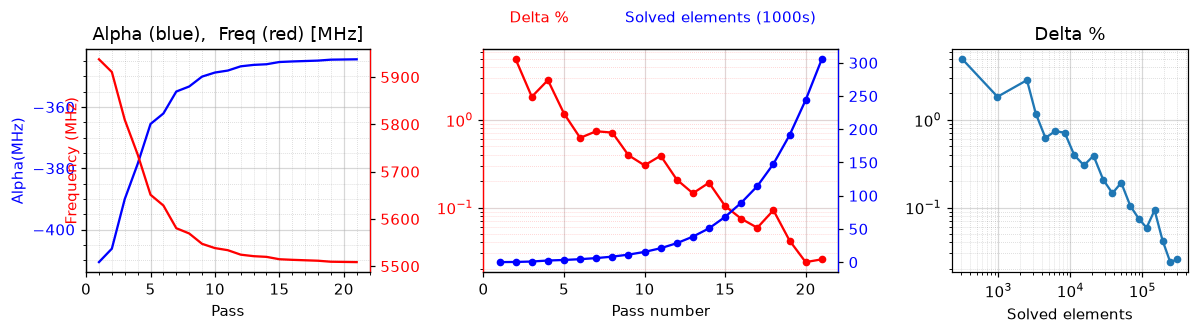

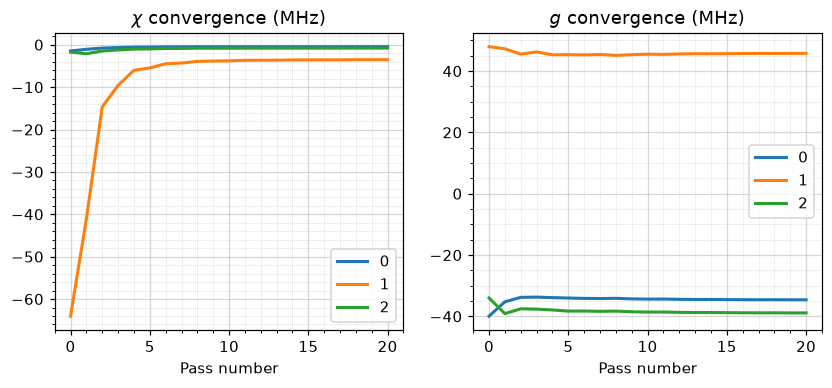

In [ ]:
lom.plot_convergence()
lom.plot_convergence_chi()

In [6]:
lom.sim.close()

Warning! 3 COM references still alive
Ansys will likely refuse to shut down


## Q2

In [10]:
qubit_name = 'q_2'

def print_qubit_properties(design, qubit_name):
    design.components[qubit_name].options.pad_width = '500 um'
    design.components[qubit_name].options.pad_height = '100 um'
    design.components[qubit_name].options.pad_gap = '40 um'
    # # print(design.components[qubit_name].options.connection_pads.resonator_pad.pad_gap)
    design.components[qubit_name].options.connection_pads.resonator_pad.pad_gap = '35 um'
    design.components[qubit_name].options.connection_pads.coupler_short_pad.pad_gap = '30 um'
    design.components[qubit_name].options.connection_pads.coupler_long_pad.pad_gap = '35 um'


    # design.components[qubit_name].options.connection_pads.resonator_pad.pad_width = '70 um'
    # design.components[qubit_name].options.connection_pads.coupler_short_pad.pad_width = '70 um'
    # design.components[qubit_name].options.connection_pads.coupler_long_pad.pad_width = '70 um'

    print("-"*50)
    print(f"Capacitive tuninig {qubit_name}")
    print("-"*50)
    print(f"pad_width = {design.components[qubit_name].options.pad_width}\npad_height = {design.components[qubit_name].options.pad_height}\npad_gap = {design.components[qubit_name].options.pad_gap}")
    print("-"*50)

    for pin in design.components[qubit_name].pin_names:
        print(f"For pin {pin}")
        print(f"    pad_width = {design.components[qubit_name].options.connection_pads[pin].pad_width}")
        print(f"    pad_height = {design.components[qubit_name].options.connection_pads[pin].pad_height}")
        print(f"    pad_gap = {design.components[qubit_name].options.connection_pads[pin].pad_gap}")
        print("-"*50)

    design.rebuild()
    
    return None

def get_side_frequencies_for_qubit(qubit_name, DESIGN_DICT):

    qubit = qubit_name.replace('_', '')

    coupler_list = [freq for name, freq in DESIGN_DICT.coupler_frequencies_ghz.items() if qubit in name]

    print(coupler_list)

    return coupler_list

In [11]:
print_qubit_properties(design, qubit_name)
get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT)

--------------------------------------------------
Capacitive tuninig q_2
--------------------------------------------------
pad_width = 500 um
pad_height = 100 um
pad_gap = 40 um
--------------------------------------------------
For pin coupler_long_pad
    pad_width = 70um
    pad_height = 30um
    pad_gap = 35 um
--------------------------------------------------
For pin coupler_short_pad
    pad_width = 70um
    pad_height = 30um
    pad_gap = 30 um
--------------------------------------------------
For pin resonator_pad
    pad_width = 70um
    pad_height = 30um
    pad_gap = 35 um
--------------------------------------------------
[6.5, 6.7]


[6.5, 6.7]

In [ ]:
from qiskit_metal.analyses import LOManalysis

lom = LOManalysis(design, 'q3d')

sweep_setup = Dict(design = design,
                        # Only simulate qubit and define its open terminations to extract exact capacitance matrix
                        run_args_dict = Dict(components=[design.components[qubit_name].name] , open_terminations=[(design.components[qubit_name].name, pad) for pad in design.components[qubit_name].pins.keys()]),
                        # LOM physics constraints (Josephson Junction Inductance & Capacitance)
                        lom_setup = Dict(junctions=Dict(Lj=12, Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz[qubit_name], freq_bus=get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT)),
                        # Ansys Q3D Iterative solver properties
                        lom_sim_setup = Dict(name = f'{qubit_name}_setup', 
                                             reuse_selected_design = True, 
                                             reuse_setup = True,
                                             freq_ghz = FOUR_QUBIT_DESIGN_DICT.qubit_frequencies_hz[qubit_name],
                                             save_fields = True, 
                                             enabled = True, 
                                             max_passes = 35, 
                                             min_passes = 2, 
                                             min_converged_passes = 3, 
                                             percent_error = 0.05, 
                                             percent_refinement = 30, 
                                             auto_increase_solution_order = True, 
                                             solution_order = 'Highest', 
                                             solver_type = 'Iterative',
                                             ))



print(sweep_setup)

lom.sim.design.rebuild()

print(print_qubit_properties(design, qubit_name))

lom.setup = sweep_setup.lom_setup
lom.sim.setup = sweep_setup.lom_sim_setup

lom.sim.run(name=qubit_name+'_capacitive', components = sweep_setup.run_args_dict.components, open_terminations = sweep_setup.run_args_dict.open_terminations, box_plus_buffer=True)
lom.run_lom()

[6.5, 6.7]
{'design': <qiskit_metal.designs.design_planar.DesignPlanar object at 0x0000025F5EC96550>, 'run_args_dict': {'components': ['q_2'], 'open_terminations': [('q_2', 'resonator_pad'), ('q_2', 'coupler_short_pad'), ('q_2', 'coupler_long_pad')]}, 'lom_setup': {'junctions': {'Lj': 12, 'Cj': 2}, 'freq_readout': 7.1, 'freq_bus': [6.5, 6.7]}, 'lom_sim_setup': {'name': 'q_2_setup', 'reuse_selected_design': True, 'reuse_setup': True, 'freq_ghz': 6.1, 'save_fields': True, 'enabled': True, 'max_passes': 35, 'min_passes': 2, 'min_converged_passes': 3, 'percent_error': 0.05, 'percent_refinement': 30, 'auto_increase_solution_order': True, 'solution_order': 'Highest', 'solver_type': 'Iterative'}}
--------------------------------------------------
Capacitive tuninig q_2
--------------------------------------------------
pad_width = 500 um
pad_height = 100 um
pad_gap = 40 um
--------------------------------------------------
For pin coupler_long_pad
    pad_width = 70um
    pad_height = 30um
  

INFO 02:06PM [connect_project]: Connecting to Ansys Desktop API...
INFO 02:06PM [load_ansys_project]: 	Opened Ansys App
INFO 02:06PM [load_ansys_project]: 	Opened Ansys Desktop v2025.1.4
INFO 02:06PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Qubit_design_project
INFO 02:06PM [connect_design]: 	Opened active design
	Design:    q_1_capacitive_q3d [Solution type: Q3D]
INFO 02:06PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 02:06PM [connect]: 	Connected to project "Qubit_design_project" and design "q_1_capacitive_q3d" 😀 



None


INFO 02:06PM [connect_design]: 	Opened active design
	Design:    q_2_capacitive_q3d [Solution type: Q3D]
WARNING 02:06PM [connect_setup]: 	No design setup detected.
WARNING 02:06PM [connect_setup]: 	Creating Q3D default setup.
INFO 02:06PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 02:06PM [get_setup]: 	Opened setup `q_2_setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 02:06PM [analyze]: Analyzing setup q_2_setup
INFO 02:30PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmpdz1niz01.txt, C, , q_2_setup:LastAdaptive, "Original", "ohm", "nH", "fF", "mSie", 6100000000, Maxwell, 1, False
INFO 02:30PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmpzoj3ic_j.txt, C, , q_2_setup:AdaptivePass, "Original", "ohm", "nH", "fF", "mSie", 6100000000, Maxwell, 1, False
INFO 02:30PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmpoqkefyuj.txt, C, , q_2_setup:AdaptivePass, "Original",

[3, 4] [5 0 1]
Predicted Values

Transmon Properties
f_Q 5.226628 [GHz]
EC 280.049795 [MHz]
EJ 13.610809 [GHz]
alpha -322.460454 [MHz]
dispersion 14.054325 [KHz]
Lq 12.000000 [nH]
Cq 69.167086 [fF]
T1 413.945041 [us]

**Coupling Properties**

tCqbus1 2.869262 [fF]
gbus1_in_MHz 41.813420 [MHz]
χ_bus1 -0.281724 [MHz]
1/T1bus1 254.364304 [Hz]
T1bus1 625.696848 [us]

tCqbus2 -3.927189 [fF]
gbus2_in_MHz -52.367735 [MHz]
χ_bus2 -0.883570 [MHz]
1/T1bus2 87.354858 [Hz]
T1bus2 1821.935796 [us]

tCqbus3 3.088261 [fF]
gbus3_in_MHz 42.469865 [MHz]
χ_bus3 -0.448038 [MHz]
1/T1bus3 42.764108 [Hz]
T1bus3 3721.694420 [us]
Bus-Bus Couplings
gbus1_2 2.020367 [MHz]
gbus1_3 1.696190 [MHz]
gbus2_3 2.009756 [MHz]


,fQ,EC,EJ,alpha,dispersion,gbus,chi_in_MHz,χr MHz,gr MHz
1,5.582489,322.331666,13.610809,-376.153263,51.033133,"[45.069105680932886, -52.939561956625305, 38.4...","[-0.5415535281429832, -1.7912324606433312, -0....",0.541554,45.069106
2,5.511793,313.660158,13.610809,-365.036933,40.036159,"[41.03977831514628, -51.317039751111444, 39.35...","[-0.404342786114071, -1.451436484293076, -0.62...",0.404343,41.039778
3,5.429052,303.68327,13.610809,-352.314313,29.891071,"[40.72103590016038, -51.246162435811236, 40.82...","[-0.3532656548930982, -1.227429461731686, -0.5...",0.353266,40.721036
4,5.376511,297.443762,13.610809,-344.393918,24.710896,"[40.259005915520994, -52.223440302030326, 40.9...","[-0.3206151295254638, -1.1528001821257667, -0....",0.320615,40.259006
5,5.329159,291.883894,13.610809,-337.359664,20.748058,"[40.64158217142168, -51.865731105227056, 41.25...","[-0.30593489421024583, -1.0411953689936644, -0...",0.305935,40.641582
6,5.30281,288.816022,13.610809,-333.487657,18.799191,"[40.66872240361572, -51.50189912864496, 41.533...","[-0.29545322796061646, -0.9784731810928367, -0...",0.295453,40.668722
7,5.280829,286.27093,13.610809,-330.280531,17.300972,"[41.0585737790604, -51.670776170902826, 41.764...","[-0.29225054456355354, -0.9466731266365802, -0...",0.292251,41.058574
8,5.268325,284.828791,13.610809,-328.465296,16.497376,"[41.10756423442051, -51.865662154846845, 41.75...","[-0.2880191169419846, -0.9327698988506962, -0....",0.288019,41.107564
9,5.256861,283.510294,13.610809,-326.806983,15.790291,"[41.15482015745747, -51.76742304178817, 41.809...","[-0.2842405001309216, -0.9105253539368114, -0....",0.284241,41.154820
10,5.24986,282.706792,13.610809,-325.796995,15.371986,"[41.37069042519571, -51.79259632607933, 42.018...","[-0.2845305008987762, -0.900207833593749, -0.4...",0.284531,41.370690


In [ ]:
lom.setup = Dict(junctions=Dict(Lj=9, Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz[qubit_name], freq_bus=get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT))
lom.run_lom()

[6.5, 6.7]
[3, 4] [5 0 1]
Predicted Values

Transmon Properties
f_Q 6.083617 [GHz]
EC 280.049795 [MHz]
EJ 18.147746 [GHz]
alpha -315.100254 [MHz]
dispersion 0.977374 [KHz]
Lq 9.000000 [nH]
Cq 69.167086 [fF]
T1 60.642002 [us]

**Coupling Properties**

tCqbus1 2.869262 [fF]
gbus1_in_MHz 44.931444 [MHz]
χ_bus1 -0.947627 [MHz]
1/T1bus1 1181.841737 [Hz]
T1bus1 134.666883 [us]

tCqbus2 -3.927189 [fF]
gbus2_in_MHz -56.272793 [MHz]
χ_bus2 -6.565005 [MHz]
1/T1bus2 1109.936374 [Hz]
T1bus2 143.391051 [us]

tCqbus3 3.088261 [fF]
gbus3_in_MHz 45.636840 [MHz]
χ_bus3 -2.294279 [MHz]
1/T1bus3 332.722019 [Hz]
T1bus3 478.342082 [us]
Bus-Bus Couplings
gbus1_2 2.020367 [MHz]
gbus1_3 1.696190 [MHz]
gbus2_3 2.009756 [MHz]


,fQ,EC,EJ,alpha,dispersion,gbus,chi_in_MHz,χr MHz,gr MHz
1,6.502393,322.331666,18.147746,-366.553425,4.375968,"[48.429905818908054, -56.88726148249902, 41.35...","[-2.993763130703372, 2722.2466723661105, -11.2...",2.993763,48.429906
2,6.419138,313.660158,18.147746,-355.924829,3.299996,"[44.10011178616002, -55.14374790673781, 42.287...","[-1.9689668404667364, -61.3000919394577, -7.12...",1.968967,44.100112
3,6.321735,303.68327,18.147746,-343.744868,2.349443,"[43.757600771019334, -55.06758527486784, 43.86...","[-1.5149713216527507, -22.416443603502906, -4....",1.514971,43.757601
4,6.259906,297.443762,18.147746,-336.154002,1.883155,"[43.26111724192496, -56.11773868494354, 44.018...","[-1.28054990421349, -15.316409095913212, -3.82...",1.280550,43.261117
5,6.204198,291.883894,18.147746,-329.407113,1.536929,"[43.67222218314548, -55.73335513772199, 44.329...","[-1.1521356214621326, -11.078393677748847, -3....",1.152136,43.672222
6,6.173204,288.816022,18.147746,-325.691171,1.37046,"[43.70138626060389, -55.342392235450944, 44.63...","[-1.078928978089388, -9.369043032119789, -2.89...",1.078929,43.701386
7,6.147353,286.27093,18.147746,-322.61218,1.244368,"[44.120308826536814, -55.523862427236544, 44.8...","[-1.0411847957181748, -8.366077898598313, -2.6...",1.041185,44.120309
8,6.132647,284.828791,18.147746,-320.869016,1.177456,"[44.17295249681312, -55.73328104571662, 44.871...","[-1.0121649875008538, -7.8973415142841, -2.572...",1.012165,44.172952
9,6.119166,283.510294,18.147746,-319.276256,1.119016,"[44.223732290809195, -55.62771624869475, 44.92...","[-0.9866601729082353, -7.423744905023992, -2.4...",0.986660,44.223732
10,6.110934,282.706792,18.147746,-318.30606,1.084643,"[44.45569998969542, -55.654766703079304, 45.15...","[-0.9803697143570868, -7.177588201372172, -2.4...",0.980370,44.455700


INFO 02:30PM [__init__]: Design "q_2_capacitive_q3d" info:
INFO 02:30PM [__init__]: 	# eigenmodes    0
	# variations    1
INFO 02:30PM [hfss_report_full_convergence]: Creating report for variation 0


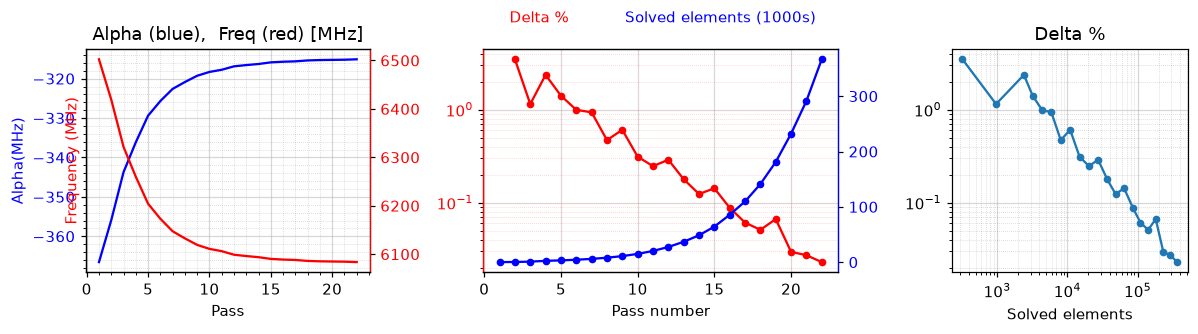

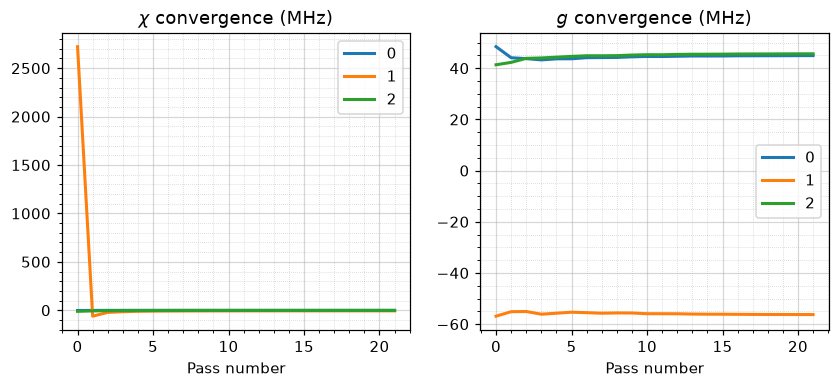

In [ ]:
lom.plot_convergence()
lom.plot_convergence_chi()

In [ ]:
import numpy as np
FOUR_QUBIT_DESIGN_DICT.simulations.capacitive.q_2 = Dict(lumped_oscillator = lom.lumped_oscillator, cap_matrix = lom.sim.capacitance_matrix)
FOUR_QUBIT_DESIGN_DICT.simulations.capacitive

{'q_0': {'lumped_oscillator': {'fQ': 5.198027045008854,
   'EC': 263.8672313949839,
   'EJ': 14.202583590033388,
   'alpha': -301.1667076080627,
   'dispersion': 5.4078859558105465,
   'gbus': array([-36.30789889,  46.26896053, -39.44866496]),
   'chi_in_MHz': array([-0.23846675, -1.46812679, -0.45611548])},
  'cap_matrix':                                      coupler_long_pad_connector_pad_q_0  \
  coupler_long_pad_connector_pad_q_0                             50.39195   
  coupler_short_pad_connector_pad_q_0                            -0.08170   
  ground_main_plane                                             -39.39882   
  pad_bot_q_0                                                    -9.06706   
  pad_top_q_0                                                    -1.33219   
  resonator_pad_connector_pad_q_0                                -0.08135   
  
                                       coupler_short_pad_connector_pad_q_0  \
  coupler_long_pad_connector_pad_q_0                    

In [ ]:
lom.sim.close()

## Q3

In [13]:
qubit_name = 'q_3'

def print_qubit_properties(design, qubit_name):
    design.components[qubit_name].options.pad_width = '500 um'
    design.components[qubit_name].options.pad_height = '100 um'
    design.components[qubit_name].options.pad_gap = '30 um'
    # # print(design.components[qubit_name].options.connection_pads.resonator_pad.pad_gap)
    design.components[qubit_name].options.connection_pads.resonator_pad.pad_gap = '35 um'
    design.components[qubit_name].options.connection_pads.coupler_short_pad.pad_gap = '30 um'
    design.components[qubit_name].options.connection_pads.coupler_long_pad.pad_gap = '35 um'


    # design.components[qubit_name].options.connection_pads.resonator_pad.pad_width = '70 um'
    # design.components[qubit_name].options.connection_pads.coupler_short_pad.pad_width = '70 um'
    # design.components[qubit_name].options.connection_pads.coupler_long_pad.pad_width = '70 um'

    print("-"*50)
    print(f"Capacitive tuninig {qubit_name}")
    print("-"*50)
    print(f"pad_width = {design.components[qubit_name].options.pad_width}\npad_height = {design.components[qubit_name].options.pad_height}\npad_gap = {design.components[qubit_name].options.pad_gap}")
    print("-"*50)

    for pin in design.components[qubit_name].pin_names:
        print(f"For pin {pin}")
        print(f"    pad_width = {design.components[qubit_name].options.connection_pads[pin].pad_width}")
        print(f"    pad_height = {design.components[qubit_name].options.connection_pads[pin].pad_height}")
        print(f"    pad_gap = {design.components[qubit_name].options.connection_pads[pin].pad_gap}")
        print("-"*50)

    design.rebuild()
    
    return None

def get_side_frequencies_for_qubit(qubit_name, DESIGN_DICT):

    qubit = qubit_name.replace('_', '')

    coupler_list = [freq for name, freq in DESIGN_DICT.coupler_frequencies_ghz.items() if qubit in name]

    print(coupler_list)

    return coupler_list

In [14]:
print_qubit_properties(design, qubit_name)
get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT)

--------------------------------------------------
Capacitive tuninig q_3
--------------------------------------------------
pad_width = 500 um
pad_height = 100 um
pad_gap = 30 um
--------------------------------------------------
For pin coupler_long_pad
    pad_width = 70um
    pad_height = 30um
    pad_gap = 35 um
--------------------------------------------------
For pin coupler_short_pad
    pad_width = 70um
    pad_height = 30um
    pad_gap = 30 um
--------------------------------------------------
For pin resonator_pad
    pad_width = 70um
    pad_height = 30um
    pad_gap = 35 um
--------------------------------------------------
[6.5, 6.7]


[6.5, 6.7]

In [ ]:
from qiskit_metal.analyses import LOManalysis

lom = LOManalysis(design, 'q3d')

sweep_setup = Dict(design = design,
                        # Only simulate qubit and define its open terminations to extract exact capacitance matrix
                        run_args_dict = Dict(components=[design.components[qubit_name].name] , open_terminations=[(design.components[qubit_name].name, pad) for pad in design.components[qubit_name].pins.keys()]),
                        # LOM physics constraints (Josephson Junction Inductance & Capacitance)
                        lom_setup = Dict(junctions=Dict(Lj=12, Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz[qubit_name], freq_bus=get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT)),
                        # Ansys Q3D Iterative solver properties
                        lom_sim_setup = Dict(name = f'{qubit_name}_setup', 
                                             reuse_selected_design = True, 
                                             reuse_setup = True,
                                             freq_ghz = FOUR_QUBIT_DESIGN_DICT.qubit_frequencies_hz[qubit_name],
                                             save_fields = True, 
                                             enabled = True, 
                                             max_passes = 35, 
                                             min_passes = 2, 
                                             min_converged_passes = 3, 
                                             percent_error = 0.05, 
                                             percent_refinement = 30, 
                                             auto_increase_solution_order = True, 
                                             solution_order = 'Highest', 
                                             solver_type = 'Iterative',
                                             ))



print(sweep_setup)

lom.sim.design.rebuild()

print(print_qubit_properties(design, qubit_name))

lom.setup = sweep_setup.lom_setup
lom.sim.setup = sweep_setup.lom_sim_setup

lom.sim.run(name=qubit_name+'_capacitive', components = sweep_setup.run_args_dict.components, open_terminations = sweep_setup.run_args_dict.open_terminations, box_plus_buffer=True)
lom.run_lom()

[6.5, 6.7]
{'design': <qiskit_metal.designs.design_planar.DesignPlanar object at 0x0000025F5EC96550>, 'run_args_dict': {'components': ['q_3'], 'open_terminations': [('q_3', 'resonator_pad'), ('q_3', 'coupler_short_pad'), ('q_3', 'coupler_long_pad')]}, 'lom_setup': {'junctions': {'Lj': 12, 'Cj': 2}, 'freq_readout': 7.3, 'freq_bus': [6.5, 6.7]}, 'lom_sim_setup': {'name': 'q_3_setup', 'reuse_selected_design': True, 'reuse_setup': True, 'freq_ghz': 5.8, 'save_fields': True, 'enabled': True, 'max_passes': 35, 'min_passes': 2, 'min_converged_passes': 3, 'percent_error': 0.05, 'percent_refinement': 30, 'auto_increase_solution_order': True, 'solution_order': 'Highest', 'solver_type': 'Iterative'}}
--------------------------------------------------
Capacitive tuninig q_3
--------------------------------------------------
pad_width = 500 um
pad_height = 100 um
pad_gap = 30 um
--------------------------------------------------
For pin coupler_long_pad
    pad_width = 70um
    pad_height = 30um
  

INFO 02:33PM [connect_project]: Connecting to Ansys Desktop API...
INFO 02:33PM [load_ansys_project]: 	Opened Ansys App
INFO 02:33PM [load_ansys_project]: 	Opened Ansys Desktop v2025.1.4
INFO 02:33PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Qubit_design_project
INFO 02:33PM [connect_design]: 	Opened active design
	Design:    q_2_capacitive_q3d [Solution type: Q3D]
INFO 02:33PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 02:33PM [connect]: 	Connected to project "Qubit_design_project" and design "q_2_capacitive_q3d" 😀 



None


INFO 02:33PM [connect_design]: 	Opened active design
	Design:    q_3_capacitive_q3d [Solution type: Q3D]
WARNING 02:33PM [connect_setup]: 	No design setup detected.
WARNING 02:33PM [connect_setup]: 	Creating Q3D default setup.
INFO 02:33PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 02:33PM [get_setup]: 	Opened setup `q_3_setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 02:33PM [analyze]: Analyzing setup q_3_setup
INFO 02:53PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmppagic6k4.txt, C, , q_3_setup:LastAdaptive, "Original", "ohm", "nH", "fF", "mSie", 5800000000, Maxwell, 1, False
INFO 02:53PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmp0_lm65oe.txt, C, , q_3_setup:AdaptivePass, "Original", "ohm", "nH", "fF", "mSie", 5800000000, Maxwell, 1, False
INFO 02:53PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Local\Temp\tmpjf47u9gr.txt, C, , q_3_setup:AdaptivePass, "Original",

[3, 4] [5 0 1]
Predicted Values

Transmon Properties
f_Q 5.080817 [GHz]
EC 263.698400 [MHz]
EJ 13.610809 [GHz]
alpha -302.036641 [MHz]
dispersion 7.857258 [KHz]
Lq 12.000000 [nH]
Cq 73.455994 [fF]
T1 621.520362 [us]

**Coupling Properties**

tCqbus1 2.836353 [fF]
gbus1_in_MHz 40.549643 [MHz]
χ_bus1 -0.184167 [MHz]
1/T1bus1 164.187163 [Hz]
T1bus1 969.350711 [us]

tCqbus2 -3.904709 [fF]
gbus2_in_MHz -49.683370 [MHz]
χ_bus2 -0.621848 [MHz]
1/T1bus2 61.334858 [Hz]
T1bus2 2594.853057 [us]

tCqbus3 3.054722 [fF]
gbus3_in_MHz 40.085478 [MHz]
χ_bus3 -0.319204 [MHz]
1/T1bus3 30.551558 [Hz]
T1bus3 5209.388834 [us]
Bus-Bus Couplings
gbus1_2 2.141557 [MHz]
gbus1_3 1.777021 [MHz]
gbus2_3 2.071937 [MHz]


,fQ,EC,EJ,alpha,dispersion,gbus,chi_in_MHz,χr MHz,gr MHz
1,5.474558,309.147405,13.610809,-359.273362,35.141697,"[37.95910287358801, -51.38314312343863, 43.407...","[-0.2661395021712657, -1.3496951256998944, -0....",0.266140,37.959103
2,5.396278,299.782502,13.610809,-347.35944,26.556853,"[40.50490967716258, -49.05110526702121, 37.700...","[-0.27323786221499696, -1.0558165042264882, -0...",0.273238,40.504910
3,5.279689,286.139292,13.610809,-330.114776,17.226286,"[39.45836319085362, -48.782086521801695, 38.41...","[-0.22314623945741333, -0.8420627558580882, -0...",0.223146,39.458363
4,5.248451,282.545241,13.610809,-325.593984,15.289015,"[39.06666270425612, -48.96195436725689, 38.002...","[-0.21026919498866803, -0.8025019509196432, -0...",0.210269,39.066663
5,5.199139,276.924408,13.610809,-318.542113,12.627057,"[38.881268858586296, -47.97112616565661, 38.40...","[-0.19580984486166433, -0.7069497970258193, -0...",0.195810,38.881269
6,5.171392,273.789821,13.610809,-314.619157,11.320006,"[39.252321102208434, -48.56464787922192, 38.81...","[-0.19281188381945105, -0.6909648611976811, -0...",0.192812,39.252321
7,5.147413,271.097282,13.610809,-311.254953,10.290048,"[39.24556625361369, -48.597235030810594, 38.77...","[-0.187128437012831, -0.6644036137192045, -0.3...",0.187128,39.245566
8,5.13806,270.051134,13.610809,-309.949217,9.911768,"[39.47416821597212, -48.571746503790735, 38.97...","[-0.187151388370784, -0.6533701102807734, -0.3...",0.187151,39.474168
9,5.123894,268.471024,13.610809,-307.978479,9.362664,"[39.87110467093034, -48.81467258247236, 39.397...","[-0.18764761840905914, -0.6444962133414871, -0...",0.187648,39.871105
10,5.112558,267.210332,13.610809,-306.407384,8.943171,"[39.87366958978632, -49.06707313965993, 39.415...","[-0.18508931603751827, -0.6390350134448205, -0...",0.185089,39.873670


In [ ]:
lom.setup = Dict(junctions=Dict(Lj=9.3, Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz[qubit_name], freq_bus=get_side_frequencies_for_qubit(qubit_name, FOUR_QUBIT_DESIGN_DICT))
lom.run_lom()

[6.5, 6.7]
[3, 4] [5 0 1]
Predicted Values

Transmon Properties
f_Q 5.811368 [GHz]
EC 263.698400 [MHz]
EJ 17.562335 [GHz]
alpha -296.126308 [MHz]
dispersion 0.697374 [KHz]
Lq 9.300000 [nH]
Cq 73.455994 [fF]
T1 165.840940 [us]

**Coupling Properties**

tCqbus1 2.836353 [fF]
gbus1_in_MHz 43.217696 [MHz]
χ_bus1 -0.422938 [MHz]
1/T1bus1 483.494826 [Hz]
T1bus1 329.176104 [us]

tCqbus2 -3.904709 [fF]
gbus2_in_MHz -52.952397 [MHz]
χ_bus2 -2.460069 [MHz]
1/T1bus2 342.541936 [Hz]
T1bus2 464.629075 [us]

tCqbus3 3.054722 [fF]
gbus3_in_MHz 42.722990 [MHz]
χ_bus3 -1.033855 [MHz]
1/T1bus3 133.647516 [Hz]
T1bus3 1190.855979 [us]
Bus-Bus Couplings
gbus1_2 2.141557 [MHz]
gbus1_3 1.777021 [MHz]
gbus2_3 2.071937 [MHz]


,fQ,EC,EJ,alpha,dispersion,gbus,chi_in_MHz,χr MHz,gr MHz
1,6.266022,309.147405,17.562335,-351.309554,3.860998,"[40.45670550315821, -54.76400999503103, 46.263...","[-0.8092936681415525, -15.400753874661717, -4....",0.809294,40.456706
2,6.175568,299.782502,17.562335,-339.847629,2.803359,"[43.17001926252571, -52.278530580686336, 40.18...","[-0.7765011771691311, -8.63144576019457, -2.42...",0.776501,43.170019
3,6.040906,286.139292,17.562335,-323.234143,1.709566,"[42.05461294923724, -51.991811155666745, 40.94...","[-0.5804620296261066, -4.876899853807313, -1.6...",0.580462,42.054613
4,6.004837,282.545241,17.562335,-318.874352,1.491741,"[41.63713966794046, -52.18351380146692, 40.503...","[-0.5352992254022388, -4.319877915018778, -1.4...",0.535299,41.637140
5,5.947911,276.924408,17.562335,-312.069947,1.198918,"[41.43954742659219, -51.12749187993047, 40.934...","[-0.48258830847087963, -3.4304986744392694, -1...",0.482588,41.439547
6,5.915884,273.789821,17.562335,-308.282726,1.058235,"[41.8350138683703, -51.76006565954288, 41.3643...","[-0.4669893757640423, -3.179904858250783, -1.2...",0.466989,41.835014
7,5.88821,271.097282,17.562335,-305.033829,0.948989,"[41.8278145696612, -51.79479695441569, 41.3298...","[-0.44664688266758995, -2.928779084484874, -1....",0.446647,41.827815
8,5.877417,270.051134,17.562335,-303.772574,0.909247,"[42.07145790073198, -51.76763135372206, 41.535...","[-0.44420949225361184, -2.8339533053444215, -1...",0.444209,42.071458
9,5.86107,268.471024,17.562335,-301.868685,0.851945,"[42.49451166243945, -52.0265412878422, 41.9898...","[-0.4416784598732693, -2.729578579707092, -1.1...",0.441678,42.494512
10,5.847989,267.210332,17.562335,-300.350635,0.808489,"[42.49724534577072, -52.29554909461194, 42.008...","[-0.43279226595147785, -2.6566861848757766, -1...",0.432792,42.497245


03:12PM 09s ERROR [plot_convergence_main]: plot_convergence_main() failed constructing pyEPR's DistributedAnalysis: 'NoneType' object has no attribute 'GetNominalVariation'. This is a known pyEPR internal bug in its variation-key handling, not a Qiskit Metal bug (see qiskit-metal#1127).


INFO 03:12PM [__del__]: Disconnected from Ansys HFSS


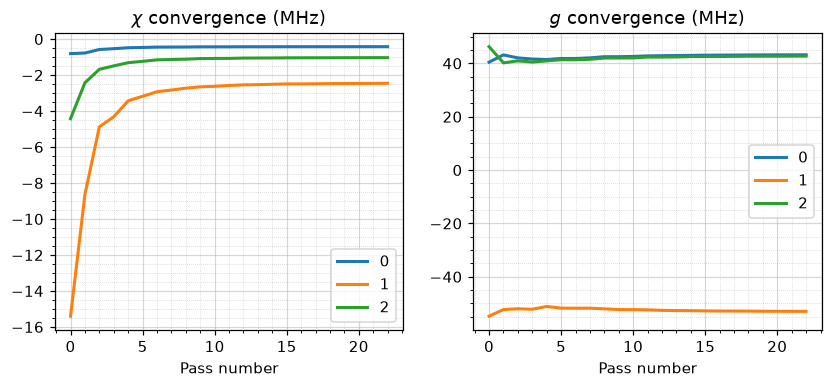

In [ ]:
lom.plot_convergence()
lom.plot_convergence_chi()

In [ ]:
import numpy as np
FOUR_QUBIT_DESIGN_DICT.simulations.capacitive.q_3 = Dict(lumped_oscillator = lom.lumped_oscillator, cap_matrix = lom.sim.capacitance_matrix)
FOUR_QUBIT_DESIGN_DICT.simulations.capacitive

{'q_0': {'lumped_oscillator': {'fQ': 5.198027045008854,
   'EC': 263.8672313949839,
   'EJ': 14.202583590033388,
   'alpha': -301.1667076080627,
   'dispersion': 5.4078859558105465,
   'gbus': array([-36.30789889,  46.26896053, -39.44866496]),
   'chi_in_MHz': array([-0.23846675, -1.46812679, -0.45611548])},
  'cap_matrix':                                      coupler_long_pad_connector_pad_q_0  \
  coupler_long_pad_connector_pad_q_0                             50.39195   
  coupler_short_pad_connector_pad_q_0                            -0.08170   
  ground_main_plane                                             -39.39882   
  pad_bot_q_0                                                    -9.06706   
  pad_top_q_0                                                    -1.33219   
  resonator_pad_connector_pad_q_0                                -0.08135   
  
                                       coupler_short_pad_connector_pad_q_0  \
  coupler_long_pad_connector_pad_q_0                    

In [ ]:
lom.sim.close()

## Save Results

In [ ]:
import pandas as pd
data_df = pd.DataFrame(FOUR_QUBIT_DESIGN_DICT.simulations.capacitive)

lom_setups = Dict(q_0 = Dict(junctions=Dict(Lj=11.5, Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz['q_0'], freq_bus=get_side_frequencies_for_qubit('q_0', FOUR_QUBIT_DESIGN_DICT)),
                  q_1 = Dict(junctions=Dict(Lj=11.5, Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz['q_1'], freq_bus=get_side_frequencies_for_qubit('q_1', FOUR_QUBIT_DESIGN_DICT)),
                  q_2 = Dict(junctions=Dict(Lj=9   , Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz['q_2'], freq_bus=get_side_frequencies_for_qubit('q_2', FOUR_QUBIT_DESIGN_DICT)),
                  q_3 = Dict(junctions=Dict(Lj=9.3 , Cj=2), freq_readout=FOUR_QUBIT_DESIGN_DICT.resonator_frequencies_ghz['q_3'], freq_bus=get_side_frequencies_for_qubit('q_3', FOUR_QUBIT_DESIGN_DICT)) 
                  )


[6.0, 6.5]
[6.0, 6.5]
[6.5, 6.7]
[6.5, 6.7]


In [ ]:
data_df = pd.DataFrame({qubit_name:FOUR_QUBIT_DESIGN_DICT.simulations.capacitive[qubit_name].lumped_oscillator for qubit_name in FOUR_QUBIT_DESIGN_DICT.simulations.capacitive.keys()})

In [ ]:
data_df

,q_0,q_1,q_2,q_3
fQ,5.198027,5.508728,6.083617,5.811368
EC,263.867231,298.520881,280.049795,263.6984
EJ,14.202584,14.202584,18.147746,17.562335
alpha,-301.166708,-344.39299,-315.100254,-296.126308
dispersion,5.407886,17.941726,0.977374,0.697374
gbus,"[-36.30789889413854, 46.26896052772059, -39.44...","[-34.59327526529563, 45.78193450494617, -38.87...","[44.93144401931824, -56.272793240666815, 45.63...","[43.2176960968659, -52.95239659574302, 42.7229..."
chi_in_MHz,"[-0.23846674973027313, -1.4681267886732572, -0...","[-0.45625844025489204, -3.5277986062085853, -0...","[-0.947626726004323, -6.565004912150474, -2.29...","[-0.422937937858104, -2.460069246716636, -1.03..."


In [ ]:
data_df.to_csv("capacitive_lom.csv")

In [ ]:
design.to_python_script(printout=True)


from qiskit_metal.qlibrary.qubits.transmon_pocket_6 import TransmonPocket6

from qiskit_metal.qlibrary.tlines.meandered import RouteMeander

from qiskit_metal.qlibrary.terminations.launchpad_wb_driven import LaunchpadWirebondDriven

from qiskit_metal.qlibrary.tlines.framed_path import RouteFramed

from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee

from qiskit_metal import designs, MetalGUI

design = designs.DesignPlanar()

gui = MetalGUI(design)


p_0 = LaunchpadWirebondDriven(
design,
name='p_0',
options={'lead_length': '50 um',
 'orientation': '-90',
 'pad_height': '80 um',
 'pad_width': '80 um',
 'pos_x': '25um',
 'pos_y': '8500um'},

component_template=None,
)




p_1 = LaunchpadWirebondDriven(
design,
name='p_1',
options={'lead_length': '50 um',
 'orientation': '-90',
 'pad_height': '80 um',
 'pad_width': '80 um',
 'pos_x': '7250um',
 'pos_y': '8500um'},

component_template=None,
)




p_2 = LaunchpadWirebondDriven(
design,
name='p_2',
options={'lead_leng

"\nfrom qiskit_metal.qlibrary.qubits.transmon_pocket_6 import TransmonPocket6\n\nfrom qiskit_metal.qlibrary.tlines.meandered import RouteMeander\n\nfrom qiskit_metal.qlibrary.terminations.launchpad_wb_driven import LaunchpadWirebondDriven\n\nfrom qiskit_metal.qlibrary.tlines.framed_path import RouteFramed\n\nfrom qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee\n\nfrom qiskit_metal import designs, MetalGUI\n\ndesign = designs.DesignPlanar()\n\ngui = MetalGUI(design)\n\n\np_0 = LaunchpadWirebondDriven(\ndesign,\nname='p_0',\noptions={'lead_length': '50 um',\n 'orientation': '-90',\n 'pad_height': '80 um',\n 'pad_width': '80 um',\n 'pos_x': '25um',\n 'pos_y': '8500um'},\n\ncomponent_template=None,\n)\n\n\n\n\np_1 = LaunchpadWirebondDriven(\ndesign,\nname='p_1',\noptions={'lead_length': '50 um',\n 'orientation': '-90',\n 'pad_height': '80 um',\n 'pad_width': '80 um',\n 'pos_x': '7250um',\n 'pos_y': '8500um'},\n\ncomponent_template=None,\n)\n\n\n\n\np_2 = LaunchpadWire

# Eigenmode


## Q0 : q_0_resonator

In [15]:
from qiskit_metal.analyses.quantization import EPRanalysis

In [16]:
component = 'q_0_resonator'
design.components[component].pin_names

{'end', 'start'}

In [18]:
eig_qb = EPRanalysis(design, "hfss")
eig_qb.sim.setup.max_passes = 40
eig_qb.sim.setup.basis_order = 1
# example: update multiple settings
eig_qb.sim.setup_update(n_modes=2, max_delta_f=0.1, min_freq_ghz=1.1, vars=Dict(Lj=design.components.q_0.options.hfss_inductance, Cj='0 fF'))
eig_qb.sim._initialize_renderer()
eig_qb.sim.setup


INFO 02:39PM [connect_project]: Connecting to Ansys Desktop API...
INFO 02:39PM [load_ansys_project]: 	Opened Ansys App
INFO 02:39PM [load_ansys_project]: 	Opened Ansys Desktop v2025.1.4
INFO 02:39PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Project9
INFO 02:39PM [connect_design]: No active design found (or error getting active design).
INFO 02:39PM [connect]: 	 Connected to project "Project9". No design detected


{'name': 'Setup',
 'reuse_selected_design': True,
 'reuse_setup': True,
 'min_freq_ghz': 1.1,
 'n_modes': 2,
 'max_delta_f': 0.1,
 'max_passes': 40,
 'min_passes': 1,
 'min_converged': 1,
 'pct_refinement': 30,
 'basis_order': 1,
 'vars': {'Lj': '10nH', 'Cj': '0 fF'}}

In [19]:
eig_qb.sim.run(name= 'q_0_resonator',
               components= [component],
               open_terminations= [(component, 'start')],
               port_list= None,
               jj_to_port= None,
               ignored_jjs= None,
               box_plus_buffer= True)


INFO 02:39PM [__del__]: Disconnected from Ansys HFSS
INFO 02:39PM [connect_design]: 	Opened active design
	Design:    q_0_resonator_hfss [Solution type: Eigenmode]
WARNING 02:39PM [connect_setup]: 	No design setup detected.
WARNING 02:39PM [connect_setup]: 	Creating eigenmode default setup.
INFO 02:39PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 02:39PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 02:39PM [analyze]: Analyzing setup Setup
02:42PM 36s INFO [get_f_convergence]: Saved convergences to c:\Users\DELL\chip-design\metal-flow\src\metal_flow\hfss_eig_f_convergence.csv


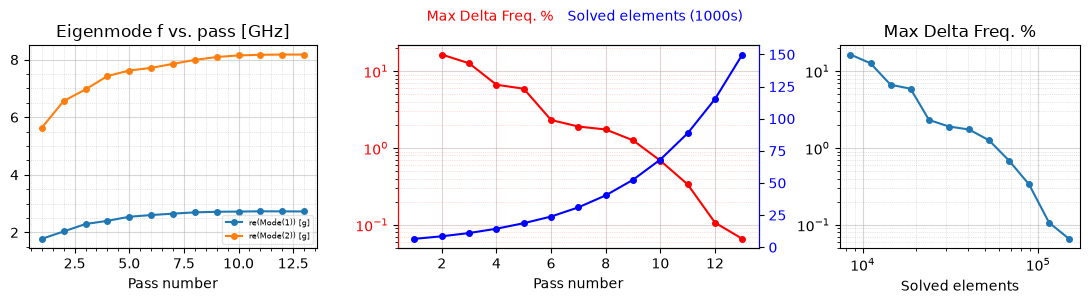

In [20]:
eig_qb.sim.plot_convergences()

In [15]:
eig_qb.sim.print_run_args()

This analysis object run with the following kwargs:
{'name': 'q_0_resonator', 'components': ['q_0_resonator'], 'open_terminations': [('q_0_resonator', 'start')], 'port_list': None, 'jj_to_port': None, 'ignored_jjs': None, 'box_plus_buffer': True}



In [16]:
eig_qb.sim.convergence_f

,re(Mode(1)) [g],re(Mode(2)) [g]
Pass [],,
1,2.145107,6.025367
2,2.266349,6.440516
3,2.397895,6.519892
4,2.485188,7.126047
5,2.577023,7.383047
6,2.631944,7.569436
7,2.676075,7.741652
8,2.707092,7.949989
9,2.728745,8.063876


INFO 01:34PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)


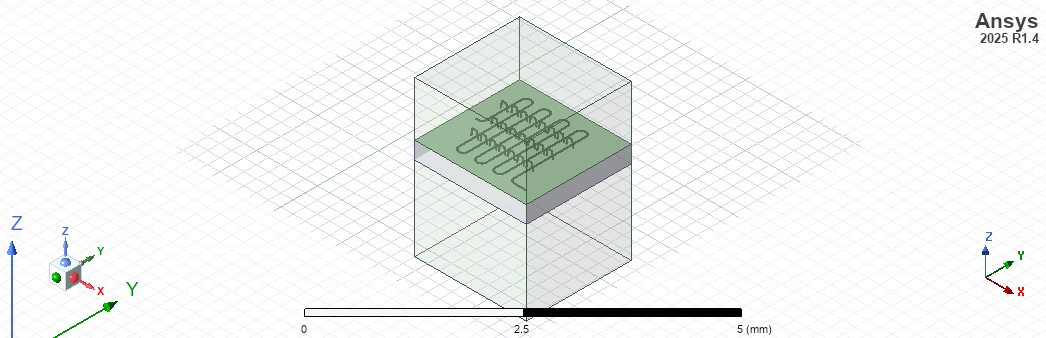

WindowsPath('c:/Users/DELL/chip-design/metal-flow/src/metal_flow/ansys.png')

In [17]:
eig_qb.sim.plot_fields("main", eigenmode=1)  
eig_qb.sim.save_screenshot()

In [21]:
eig_qb.sim.close()

## Q_0 : c_q0_q1

In [6]:
from qiskit_metal.analyses.quantization import EPRanalysis

In [7]:
component = 'c_q0_q1'
design.components[component].pin_names

{'end', 'start'}

In [8]:
eig_qb = EPRanalysis(design, "hfss")
eig_qb.sim.setup.max_passes = 40
eig_qb.sim.setup.basis_order = 1
# example: update multiple settings
eig_qb.sim.setup_update(n_modes=2, max_delta_f=0.1, min_freq_ghz=1.1, vars=Dict(Lj=design.components.q_0.options.hfss_inductance, Cj='0 fF'))
eig_qb.sim._initialize_renderer()
eig_qb.sim.setup


INFO 09:39PM [connect_project]: Connecting to Ansys Desktop API...
INFO 09:39PM [load_ansys_project]: 	Opened Ansys App
INFO 09:39PM [load_ansys_project]: 	Opened Ansys Desktop v2025.1.4
INFO 09:39PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Project4
INFO 09:39PM [connect_design]: No active design found (or error getting active design).
INFO 09:39PM [connect]: 	 Connected to project "Project4". No design detected


{'name': 'Setup',
 'reuse_selected_design': True,
 'reuse_setup': True,
 'min_freq_ghz': 1.1,
 'n_modes': 2,
 'max_delta_f': 0.1,
 'max_passes': 40,
 'min_passes': 1,
 'min_converged': 1,
 'pct_refinement': 30,
 'basis_order': 1,
 'vars': {'Lj': '10nH', 'Cj': '0 fF'}}

In [9]:
eig_qb.sim.run(name=component,
               components= [component],
               open_terminations= [(component, 'start'),(component, 'end')],
               port_list= None,
               jj_to_port= None,
               ignored_jjs= None,
               box_plus_buffer= True)


INFO 09:39PM [connect_design]: 	Opened active design
	Design:    c_q0_q1_hfss [Solution type: Eigenmode]
WARNING 09:39PM [connect_setup]: 	No design setup detected.
WARNING 09:39PM [connect_setup]: 	Creating eigenmode default setup.
INFO 09:39PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 09:39PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 09:39PM [analyze]: Analyzing setup Setup
09:43PM 37s INFO [get_f_convergence]: Saved convergences to c:\Users\DELL\chip-design\metal-flow\src\metal_flow\hfss_eig_f_convergence.csv


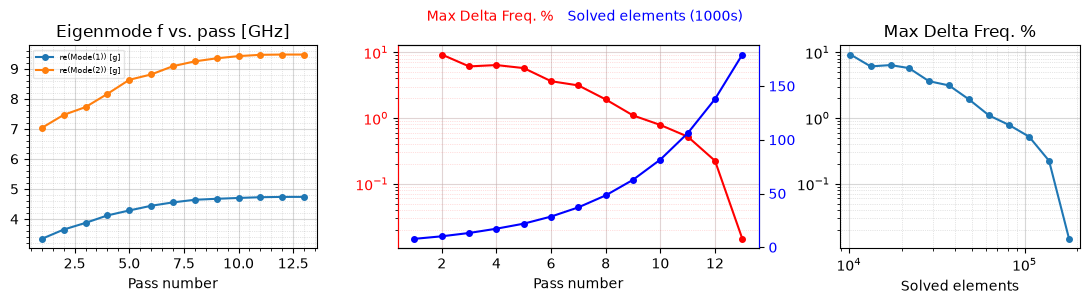

In [42]:
eig_qb.sim.plot_convergences()

In [43]:
eig_qb.sim.print_run_args()

This analysis object run with the following kwargs:
{'name': 'c_q0_q1', 'components': ['c_q0_q1'], 'open_terminations': [('c_q0_q1', 'start'), ('c_q0_q1', 'end')], 'port_list': None, 'jj_to_port': None, 'ignored_jjs': None, 'box_plus_buffer': True}



In [44]:
eig_qb.sim.convergence_f

,re(Mode(1)) [g],re(Mode(2)) [g]
Pass [],,
1,3.341117,7.032431
2,3.649643,7.464717
3,3.872222,7.723753
4,4.119670,8.162410
5,4.284991,8.631440
6,4.440706,8.808710
7,4.553374,9.084828
8,4.640809,9.244517
9,4.673041,9.345910


INFO 03:01PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)


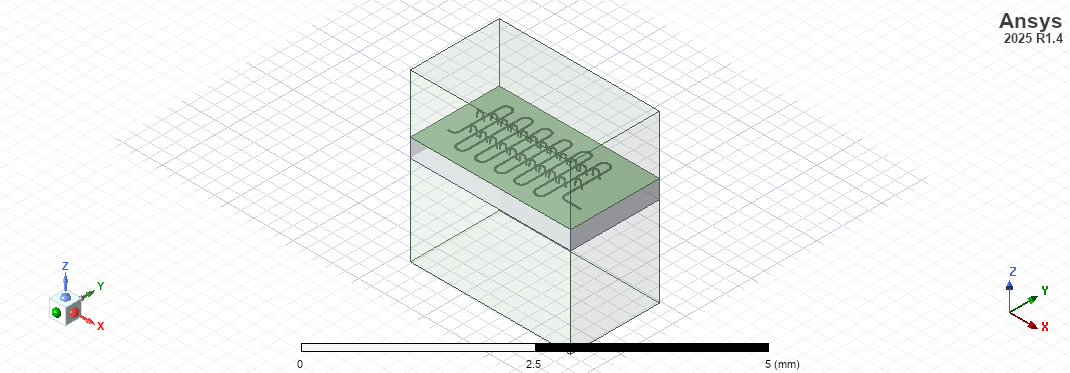

WindowsPath('c:/Users/DELL/chip-design/metal-flow/src/metal_flow/ansys.png')

In [45]:
eig_qb.sim.plot_fields("main", eigenmode=1)  
eig_qb.sim.save_screenshot()

In [10]:
eig_qb.sim.close()

## Q_0 : c_q0_q2

In [29]:
from qiskit_metal.analyses.quantization import EPRanalysis

In [30]:
component = 'c_q0_q2'
design.components[component].pin_names

{'end', 'start'}

In [31]:
eig_qb = EPRanalysis(design, "hfss")
eig_qb.sim.setup.max_passes = 40
eig_qb.sim.setup.basis_order = 1
# example: update multiple settings
eig_qb.sim.setup_update(n_modes=2, max_delta_f=0.1, min_freq_ghz=1.1, vars=Dict(Lj=design.components.q_0.options.hfss_inductance, Cj='0 fF'))
eig_qb.sim._initialize_renderer()
eig_qb.sim.setup


INFO 01:44PM [connect_project]: Connecting to Ansys Desktop API...
INFO 01:44PM [load_ansys_project]: 	Opened Ansys App
INFO 01:44PM [load_ansys_project]: 	Opened Ansys Desktop v2025.1.4
INFO 01:44PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Test_design_project


INFO 01:44PM [connect_design]: 	Opened active design
	Design:    c_q0_q1_hfss [Solution type: Eigenmode]
INFO 01:44PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 01:44PM [connect]: 	Connected to project "Test_design_project" and design "c_q0_q1_hfss" 😀 



{'name': 'Setup',
 'reuse_selected_design': True,
 'reuse_setup': True,
 'min_freq_ghz': 1.1,
 'n_modes': 2,
 'max_delta_f': 0.1,
 'max_passes': 40,
 'min_passes': 1,
 'min_converged': 1,
 'pct_refinement': 30,
 'basis_order': 1,
 'vars': {'Lj': '10 nH', 'Cj': '0 fF'}}

In [32]:
eig_qb.sim.run(name=component,
               components= [component],
               open_terminations= [(component, 'start'),(component, 'end')],
               port_list= None,
               jj_to_port= None,
               ignored_jjs= None,
               box_plus_buffer= True)


INFO 01:44PM [connect_design]: 	Opened active design
	Design:    c_q0_q2_hfss [Solution type: Eigenmode]
INFO 01:44PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 01:44PM [analyze]: Analyzing setup Setup
01:48PM 34s INFO [get_f_convergence]: Saved convergences to c:\Users\DELL\chip-design\metal-flow\src\metal_flow\hfss_eig_f_convergence.csv


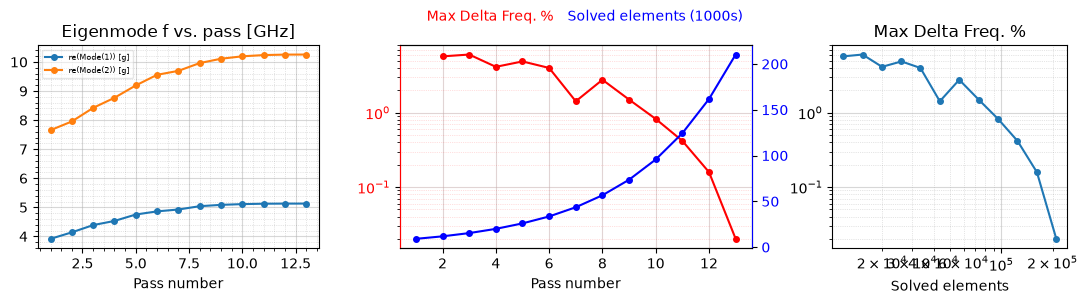

In [33]:
eig_qb.sim.plot_convergences()

In [34]:
eig_qb.sim.print_run_args()

This analysis object run with the following kwargs:
{'name': 'c_q0_q2', 'components': ['c_q0_q2'], 'open_terminations': [('c_q0_q2', 'start'), ('c_q0_q2', 'end')], 'port_list': None, 'jj_to_port': None, 'ignored_jjs': None, 'box_plus_buffer': True}



In [35]:
eig_qb.sim.convergence_f

,re(Mode(1)) [g],re(Mode(2)) [g]
Pass [],,
1,3.915616,7.653951
2,4.138889,7.953980
3,4.388512,8.421369
4,4.531134,8.768681
5,4.752036,9.192932
6,4.860405,9.559119
7,4.924760,9.694875
8,5.038494,9.962837
9,5.084445,10.111902


INFO 01:48PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)


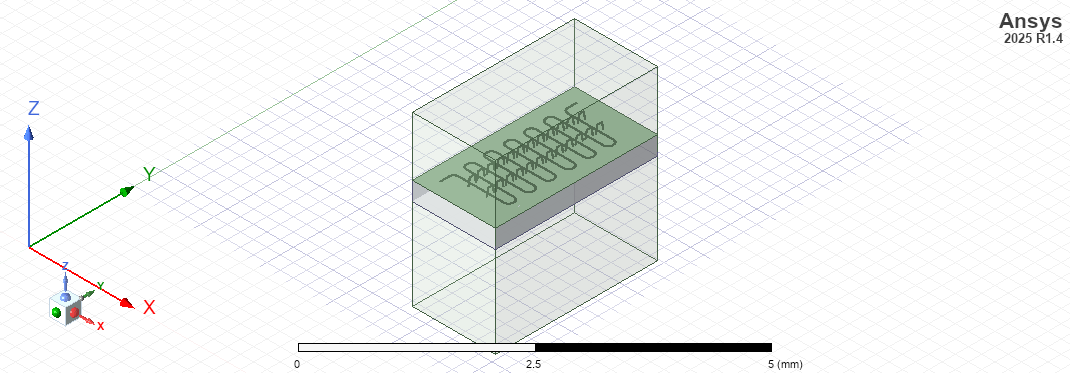

WindowsPath('c:/Users/DELL/chip-design/metal-flow/src/metal_flow/ansys.png')

In [36]:
eig_qb.sim.plot_fields("main", eigenmode=1)  
eig_qb.sim.save_screenshot()

In [37]:
eig_qb.sim.close()

Warning! 3 COM references still alive
Ansys will likely refuse to shut down


## Q_0 + 3 resonators

In [10]:
from qiskit_metal.analyses.quantization import EPRanalysis

In [11]:
design.components.q_0.options.hfss_inductance = '10 nH'



design.rebuild()

In [14]:
qubit_name = 'q_0'
eig_qb = EPRanalysis(design, "hfss")
eig_qb.sim.setup.max_passes = 40
eig_qb.sim.setup.basis_order = -1
# example: update multiple settings
eig_qb.sim.setup_update(n_modes=4, 
                        max_delta_f=0.1, 
                        min_freq_ghz=1.1,
                        pct_refinement=20, 
                        vars=Dict(Lj=design.components.q_0.options.hfss_inductance, Cj='0 fF'))

print(eig_qb.sim.setup)
eig_qb.sim._initialize_renderer()

INFO 02:15AM [connect_project]: Connecting to Ansys Desktop API...
INFO 02:15AM [load_ansys_project]: 	Opened Ansys App
INFO 02:15AM [load_ansys_project]: 	Opened Ansys Desktop v2025.1.4
INFO 02:15AM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Bowtie
INFO 02:15AM [connect_design]: 	Opened active design
	Design:    q_0_capacitive_q3d [Solution type: Q3D]
INFO 02:15AM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 02:15AM [connect]: 	Connected to project "Bowtie" and design "q_0_capacitive_q3d" 😀 



{'name': 'Setup', 'reuse_selected_design': True, 'reuse_setup': True, 'min_freq_ghz': 1.1, 'n_modes': 4, 'max_delta_f': 0.1, 'max_passes': 40, 'min_passes': 1, 'min_converged': 1, 'pct_refinement': 20, 'basis_order': -1, 'vars': {'Lj': '10 nH', 'Cj': '0 fF'}}


In [15]:
eig_qb.sim.run(name=qubit_name+"_eigenmode", components=[qubit_name, qubit_name+"_resonator", 'c_q0_q1', 'c_q0_q2'], open_terminations=[('q_0_resonator', 'end'), ('c_q0_q1', 'end'), ('c_q0_q2', 'end')], box_plus_buffer=True)


INFO 02:15AM [connect_design]: 	Opened active design
	Design:    q_0_eigenmode_hfss [Solution type: Eigenmode]
WARNING 02:15AM [connect_setup]: 	No design setup detected.
WARNING 02:15AM [connect_setup]: 	Creating eigenmode default setup.
INFO 02:15AM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 02:16AM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 02:16AM [analyze]: Analyzing setup Setup
06:11AM 47s INFO [get_f_convergence]: Saved convergences to c:\Users\DELL\chip-design\metal-flow\src\metal_flow\hfss_eig_f_convergence.csv


INFO 10:00AM [__del__]: Disconnected from Ansys HFSS


INFO 10:00AM [__del__]: Disconnected from Ansys HFSS


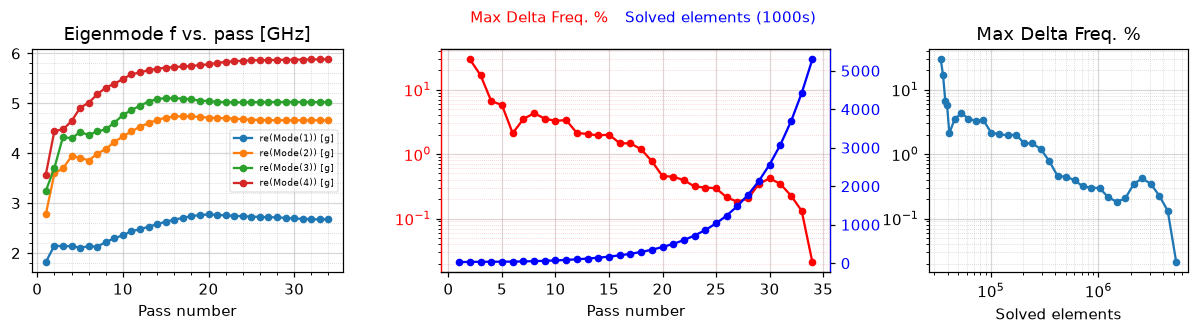

In [16]:
eig_qb.sim.plot_convergences()

In [17]:
eig_qb.sim.print_run_args()

This analysis object run with the following kwargs:
{'name': 'q_0_eigenmode', 'components': ['q_0', 'q_0_resonator', 'c_q0_q1', 'c_q0_q2'], 'open_terminations': [('q_0_resonator', 'end'), ('c_q0_q1', 'end'), ('c_q0_q2', 'end')], 'port_list': None, 'jj_to_port': None, 'ignored_jjs': None, 'box_plus_buffer': True}



In [18]:
eig_qb.sim.convergence_f

,re(Mode(1)) [g],re(Mode(2)) [g],re(Mode(3)) [g],re(Mode(4)) [g]
Pass [],,,,
1,1.817893,2.776366,3.243617,3.571789
2,2.150473,3.594627,3.705479,4.447383
3,2.133286,3.694833,4.325453,4.475865
4,2.140487,3.939394,4.298379,4.641849
5,2.108835,3.913567,4.422715,4.909779
6,2.133484,3.854249,4.368802,5.012980
7,2.127793,3.988828,4.435712,5.178490
8,2.219321,4.083620,4.479005,5.316084
9,2.295887,4.228205,4.613424,5.391585


INFO 10:30AM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)


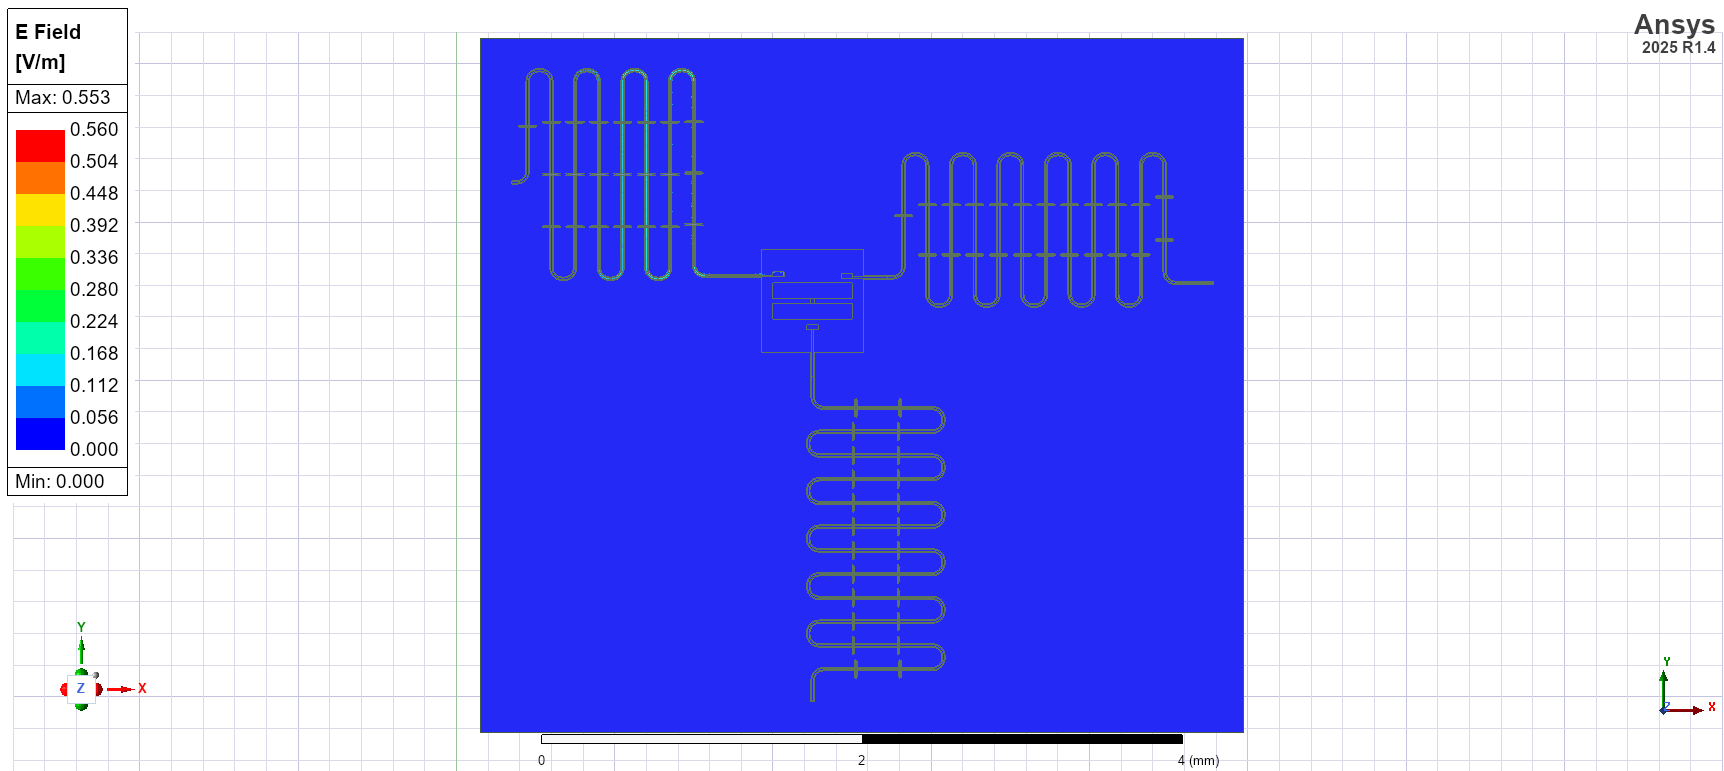

WindowsPath('c:/Users/DELL/chip-design/metal-flow/src/metal_flow/ansys.png')

In [21]:
eig_qb.sim.plot_fields("main", eigenmode=1)
eig_qb.sim.save_screenshot()

INFO 10:32AM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)


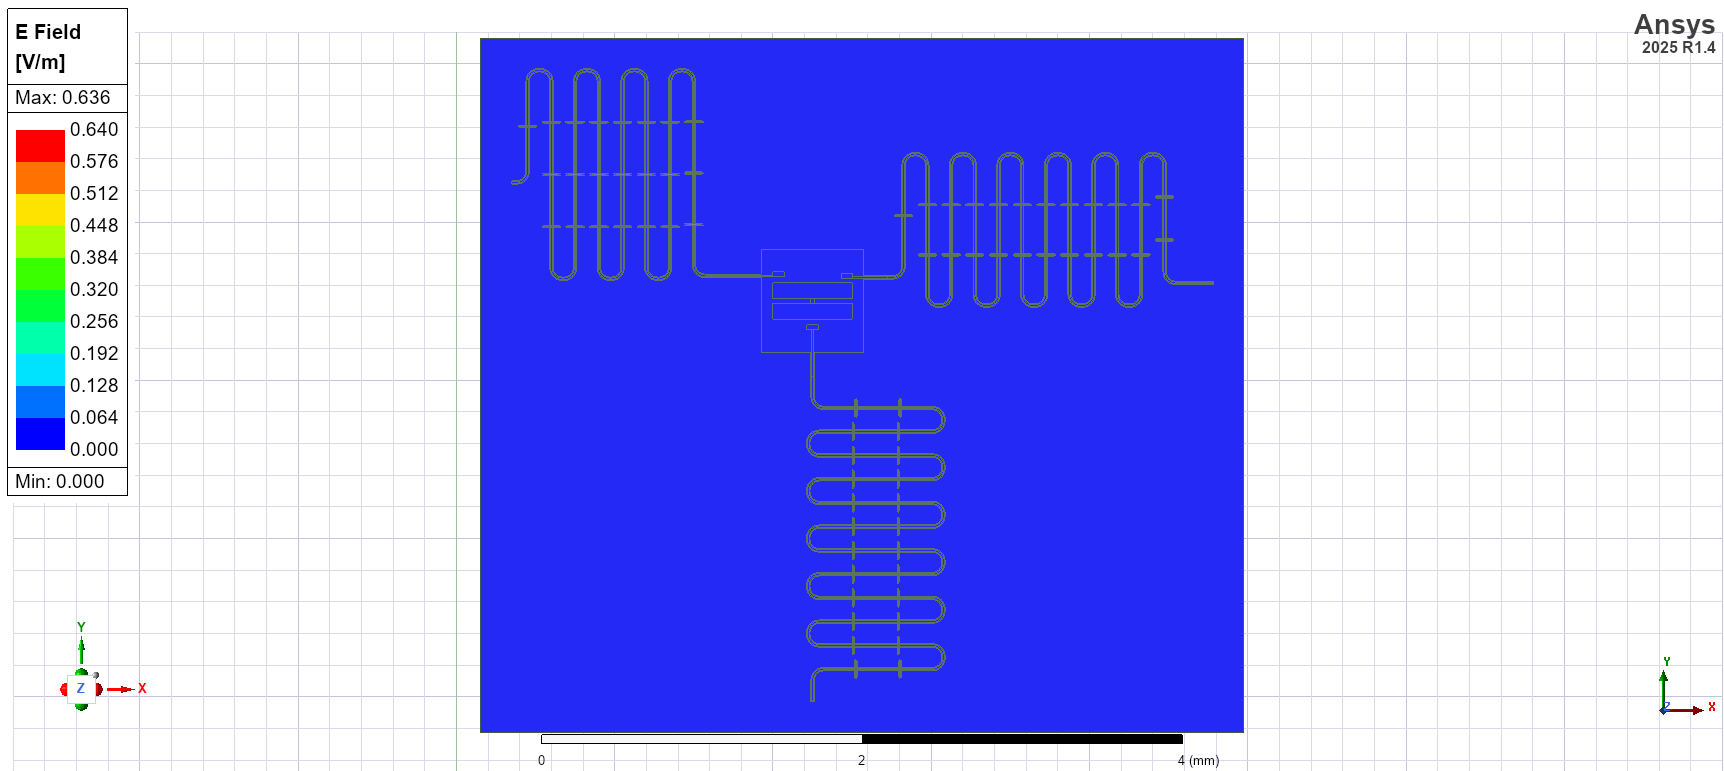

WindowsPath('c:/Users/DELL/chip-design/metal-flow/src/metal_flow/ansys.png')

In [22]:
eig_qb.sim.plot_fields("main", eigenmode=2)  
eig_qb.sim.save_screenshot()

In [23]:
eig_qb.sim.plot_fields("main", eigenmode=3)  
eig_qb.sim.save_screenshot()

INFO 10:56AM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
10:58AM 32s ERROR [save_screenshot]: save_screenshot() failed talking to the Ansys COM interface: (-2147023170, 'The remote procedure call failed.', None, None). This is a known Ansys/pyEPR COM reliability issue, not a Qiskit Metal bug (see qiskit-metal#1046, #1130). It is often transient -- try again, or make sure the AEDT window has focus and no other automation is attached to the same session.


INFO 04:56PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)


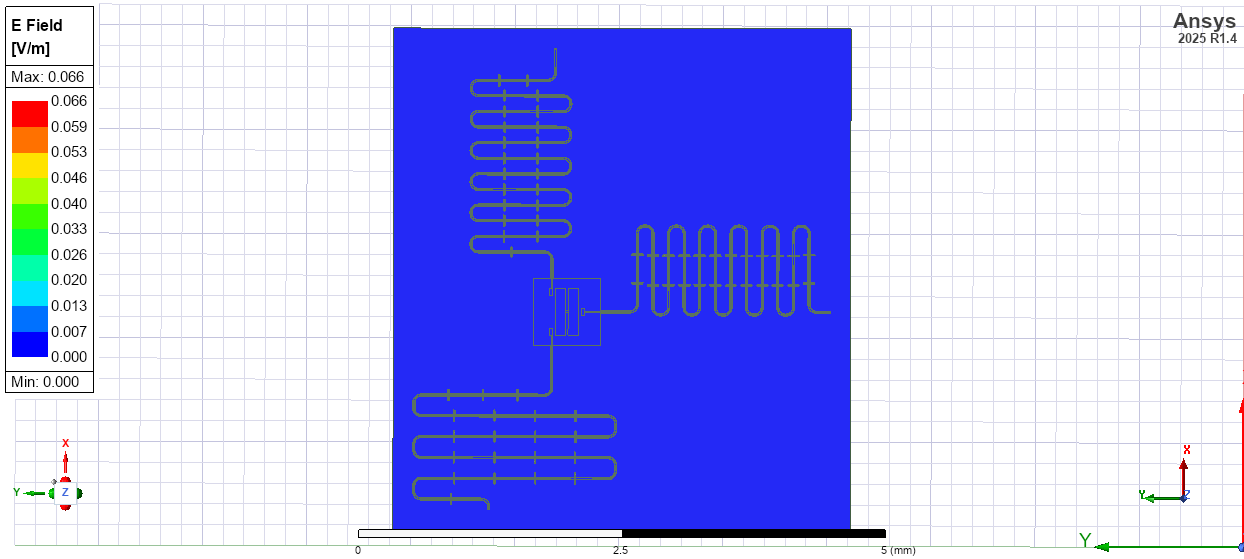

WindowsPath('c:/Users/DELL/chip-design/metal-flow/src/metal_flow/ansys.png')

In [34]:
eig_qb.sim.plot_fields("main", eigenmode=4)  
eig_qb.sim.save_screenshot()

In [35]:
eig_qb.setup.junctions.jj.rect = f"JJ_rect_Lj_{qubit_name}_rect_jj"
eig_qb.setup.junctions.jj.line = f"JJ_Lj_{qubit_name}_rect_jj_"
eig_qb.setup

{'junctions': {'jj': {'Lj_variable': 'Lj',
   'Cj_variable': 'Cj',
   'rect': 'JJ_rect_Lj_q_0_rect_jj',
   'line': 'JJ_Lj_q_0_rect_jj_'}},
 'dissipatives': {'dielectrics_bulk': ['main']},
 'cos_trunc': 8,
 'fock_trunc': 7,
 'sweep_variable': 'Lj'}

INFO 06:28PM [__init__]: Design "q_0_eigenmode_hfss" info:
INFO 06:28PM [__init__]: 	# eigenmodes    4
	# variations    1
INFO 06:28PM [__init__]: Design "q_0_eigenmode_hfss" info:
INFO 06:28PM [__init__]: 	# eigenmodes    4
	# variations    1
INFO 06:29PM [do_EPR_analysis]: Variation 0  [1/1]



        energy_elec_all       = 2.51373813018458e-27
        energy_elec_substrate = 2.3484889317843e-27
        EPR of substrate = 93.4%

        energy_mag    = 1.59547156848429e-24
        energy_mag % of energy_elec_all  = 63470.1%
        


INFO 06:31PM [do_EPR_analysis]: Mode 0 at 2.67 GHz   [1/4]
INFO 06:31PM [do_EPR_analysis]:     Calculating E_magnetic ...
INFO 06:32PM [do_EPR_analysis]:     Calculating E_electric ...
INFO 06:32PM [do_EPR_analysis]:      (E_E-E_H)/E_E=-5956.4%   E_E= 5.79e-25   E_H=3.507e-23
INFO 06:32PM [do_EPR_analysis]:     Calculating junction EPR, method=`line_voltage`
INFO 06:32PM [do_EPR_analysis]: 	junction        EPR p_0j   sign s_0j    (p_capacitive)
INFO 06:32PM [calc_p_junction]: 	jj              4.49251e-05  (-)        2.52302e-07
INFO 06:32PM [calc_p_junction]: 		(U_tot_cap-U_tot_ind)/mean=-96.75%
WARNING 06:32PM [calc_p_junction]: This simulation may not have converged: the difference in total cap and ind energies is 96.8% (>15%). Proceed with caution.
INFO 06:32PM [get_Qdielectric]: Calculating Qdielectric_main for mode 0 (0/3)
INFO 06:32PM [get_Qdielectric]: p_dielectric_main_0 = 0.9199299107052614
INFO 06:34PM [do_EPR_analysis]: Mode 1 at 4.65 GHz   [2/4]
INFO 06:34PM [do_EPR_analysi

   4.5e-05
   0.00054
    0.0015
         1
   1.1e-07 4.61e-06 1.36e-05   0.0108
  4.61e-06 4.83e-05 0.000286    0.226
  1.36e-05 0.000286 0.000423    0.671
    0.0108    0.226    0.671      265
 1.94e-07+0j1.14e-05+0j4.36e-05+0j0.0165+0j
 1.14e-05+0j0.000177+0j0.0014+0j 0.605+0j
 4.36e-05+0j0.0014+0j0.00285+0j  3.04+0j
 0.0165+0j 0.605+0j  3.04+0j   291+0j


INFO 06:41PM [__del__]: Disconnected from Ansys HFSS


...

###### Numerical diagonalization

Lj,10
0,2666.98+ 0.00j
1,4652.63+ 0.00j
2,5022.47+ 0.00j
3,5634.58+ 0.00j


#### Kerr Non-linear coefficient table (MHz)

###### Numerical diagonalization

0                               1  \
Lj                                                                     
10 0  1.94e-07+0.00e+            00j  1.14e-05+0.00e+            00j   
   1  1.14e-05+0.00e+            00j  1.77e-04+0.00e+            00j   
   2  4.36e-05+0.00e+            00j  1.40e-03+0.00e+            00j   
   3  1.65e-02+0.00e+            00j  6.05e-01+0.00e+            00j   

                                   2               3  
Lj                                                    
10 0  4.36e-05+0.00e+            00j    0.02+  0.00j  
   1  1.40e-03+0.00e+            00j    0.61+  0.00j  
   2  2.85e-03+0.00e+            00j    3.04+  0.00j  
   3  3.04e+00+0.00e+            00j  291.02+  0.00j

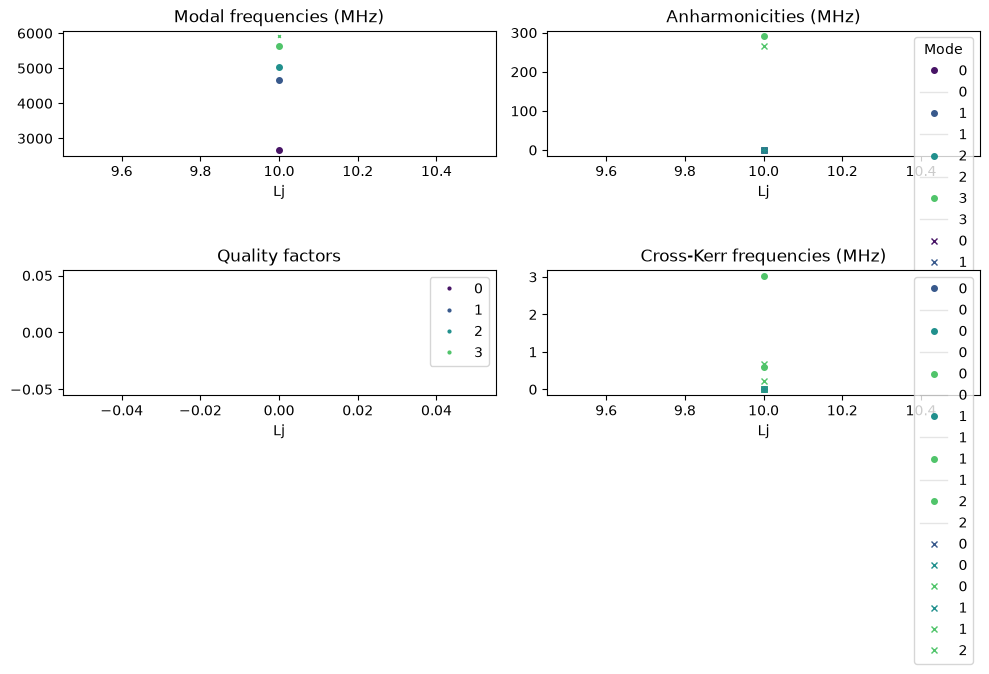

In [36]:
eig_qb.run_epr()

In [30]:
eig_qb.sim.close()

Warning! 6 COM references still alive
Ansys will likely refuse to shut down


# Rough

In [ ]:
cap_sweep.perform_sweep(name = f'pad_width_sweep', sweep_component_options = design.components.q0.options,
                                        sweep_variable = 'pad_width',
                                        sweep_values = [ str(450+(i*10))+'um' for i in range(-5, 6) ])

In [ ]:
import h5py
import numpy as np
import pandas as pd


def _decode_structured_array(arr: np.ndarray) -> pd.DataFrame:
    """
    Convert a numpy structured array (as written by to_records()) back into
    a DataFrame, decoding any bytes columns (from h5py |S storage) to str.
    """
    df = pd.DataFrame(arr)
    for col in df.columns:
        if df[col].dtype.kind == 'S':  # byte-string columns
            df[col] = df[col].str.decode('utf-8')
        elif df[col].dtype == object:
            # in case some values are bytes objects individually
            df[col] = df[col].apply(lambda x: x.decode('utf-8') if isinstance(x, bytes) else x)
    return df


def load_sweep_h5(h5_path: str) -> dict:
    """
    Reads a sweep .h5 file produced by Capacitence_Sweeper.perform_sweep()
    and returns a dict keyed by group name (e.g. 'pad_width_400um'), each
    containing:
        - 'capacitance_matrix': np.ndarray
        - 'cap_mat_all_passes': dict[str, np.ndarray]
        - 'iter_details': pd.DataFrame (1 row)
        - 'lom_details': pd.DataFrame
    """
    results = {}

    with h5py.File(h5_path, 'r') as f:
        for group_name in f.keys():
            group = f[group_name]

            entry = {}

            # Capacitance matrix (plain ndarray)
            entry['capacitance_matrix'] = group['capacitance_matrix'][:]

            # All-pass capacitance matrices (plain ndarrays, one per pass)
            cap_all_passes = {}
            if 'cap_mat_all_passes' in group:
                cap_group = group['cap_mat_all_passes']
                for pass_key in cap_group.keys():
                    cap_all_passes[pass_key] = cap_group[pass_key][:]
            entry['cap_mat_all_passes'] = cap_all_passes

            # iter_details (structured array -> DataFrame, decode strings)
            entry['iter_details'] = _decode_structured_array(group['iter_details'][:])

            # lom_details (structured array -> DataFrame, decode strings)
            entry['lom_details'] = _decode_structured_array(group['lom_details'][:])

            results[group_name] = entry

    return results


# --- Usage ---
data = load_sweep_h5('pad_width_sweep_data.h5')

# Example: build a single summary DataFrame across all sweep points
summary_rows = []
for group_name, entry in data.items():
    summary_rows.append(entry['iter_details'].iloc[0])

summary_df = pd.DataFrame(summary_rows).reset_index(drop=True)
summary_df

=== Design-space corners (L_J in [8,12] nH, EJ/EC > 50) ===
L_J=8 nH corner: f01=7.764 GHz, alpha=408.7 MHz  (r=50 exactly)
L_J=12 nH corner: f01=5.176 GHz, alpha=272.4 MHz  (r=50 exactly)

Achievable bounding ranges over the whole design space:
  f01   in [0, 7.76] GHz (practically useful band roughly 5.18-7.76 GHz)
  alpha in [0, 408.7] MHz (practically useful band roughly 272-409 MHz)

Spot checks:
  L_J at (5GHz, 200MHz)  = 9.67 nH,  r = 84.5
  L_J at (6GHz, 300MHz)  = 9.88 nH,  r = 55.1


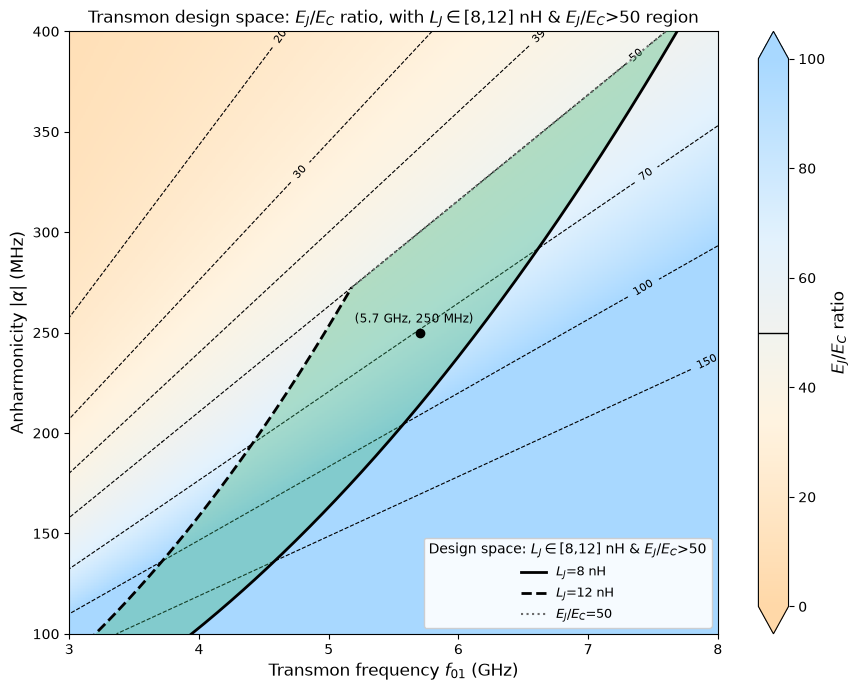

In [59]:
%matplotlib inline
"""
Transmon EJ/EC ratio as a function of target frequency (f01) and anharmonicity (alpha).

Closed-form relation (from second-order perturbation theory):
    f01   = [sqrt(8*Ej*Ec) - Ec] / h
    alpha = -Ec / h                      (leading order)

Let A = Ec/h  (anharmonicity magnitude, same units as f01, e.g. GHz).
Solving the first equation for Ej/h:
    Ej/h = (f01 + A)^2 / (8*A)

The EJ/EC ratio is then:
    r = (Ej/h) / (Ec/h) = (Ej/h) / A
      = (f01 + A)^2 / (8*A^2)

This is fully analytic -- no root-finding needed.
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ----------------------------------------------------------------------
# 1. Build the (frequency, anharmonicity) grid
# ----------------------------------------------------------------------
f01_ghz = np.linspace(3.0, 8.0, 400)          # transmon frequency axis [GHz]
alpha_mhz = np.linspace(100.0, 400.0, 400)    # anharmonicity axis [MHz]

F, ALPHA_MHZ = np.meshgrid(f01_ghz, alpha_mhz)   # F, ALPHA_MHZ both in "display" units
A = ALPHA_MHZ / 1000.0                            # convert anharmonicity to GHz for the formula

# ----------------------------------------------------------------------
# 2. Closed-form EJ/EC ratio
# ----------------------------------------------------------------------
R = (F + A) ** 2 / (8.0 * A ** 2)

# ----------------------------------------------------------------------
# 2b. Closed-form junction inductance L_J
#     Ej/h = (f01+A)^2 / (8A)              [Hz, with f01,A in Hz]
#     L_J  = phi0^2 / (h * Ej/h) = K / (Ej/h),   K = phi0^2/h
# ----------------------------------------------------------------------
hbar = 1.054571817e-34   # J s
e_charge = 1.602176634e-19   # C
h_planck = 6.62607015e-34    # J s
phi0 = hbar / (2 * e_charge)          # reduced flux quantum, Wb
K_const = phi0 ** 2 / h_planck        # Ohm

F_hz = F * 1e9          # frequency axis in Hz
A_hz = A * 1e9          # anharmonicity axis in Hz

Ej_over_h = (F_hz + A_hz) ** 2 / (8.0 * A_hz)     # Hz
LJ = K_const / Ej_over_h                           # Henry
LJ_nH = LJ * 1e9

LJ_MIN, LJ_MAX = 8.0, 12.0   # nH -- fabrication/design constraint
R_MIN = 50.0                  # EJ/EC design-regime constraint

# ----------------------------------------------------------------------
# 2c. Analytic design-space polygon
#
# Now L_J is fixed by geometry (junction), NOT anharmonicity (which floats
# with capacitance geometry and can't be pinned down independently). So:
#   - For a given L_J,  Ej/h = K_const / L_J   is FIXED.
#   - Sweeping Ec (i.e. alpha) from 0 upward traces a curve in (f01, alpha):
#         f01 = sqrt(8*(Ej/h)*Ec) - Ec ,      alpha = Ec
#   - The r = Ej/Ec > 50 constraint caps Ec at Ec_max = (Ej/h)/50, i.e. it
#     caps how far along that curve you can go.
#   - Because r=50 is a straight line in this plane (f01 = (sqrt(8*50)-1)*alpha
#     = 19*alpha), the achievable region for L_J in [LJ_MIN, LJ_MAX] AND
#     r>50 is a curvy triangle with vertices at:
#         (0,0) -- origin
#         corner where the L_J_MAX curve meets the r=50 line
#         corner where the L_J_MIN curve meets the r=50 line
#   - Its three edges are: the L_J_MAX curve, the r=50 line, and the
#     L_J_MIN curve.
# ----------------------------------------------------------------------
def ej_over_h(lj_nH):
    return K_const / (lj_nH * 1e-9)   # Hz

def curve_f01_alpha(lj_nH, n=300):
    """f01(Hz), alpha(Hz) along L_J=const, for Ec in (0, Ec_max] where r=50 caps it."""
    ej = ej_over_h(lj_nH)
    ec_max = ej / R_MIN
    ec = np.linspace(1e-6 * ec_max, ec_max, n)   # avoid exact zero
    f01 = np.sqrt(8 * ej * ec) - ec
    return f01, ec   # both in Hz

f01_ljmin, alpha_ljmin = curve_f01_alpha(LJ_MIN)   # lower-right edge (larger Ej -> larger f01)
f01_ljmax, alpha_ljmax = curve_f01_alpha(LJ_MAX)   # upper-left edge (smaller Ej -> smaller f01)

# Build the closed polygon: origin -> up the L_J_MAX curve -> across (r=50 line,
# automatically satisfied since both curves already end exactly on r=50) ->
# back down the L_J_MIN curve (reversed) -> origin
poly_f01_hz = np.concatenate([[0.0], f01_ljmax, f01_ljmin[::-1], [0.0]])
poly_alpha_hz = np.concatenate([[0.0], alpha_ljmax, alpha_ljmin[::-1], [0.0]])

poly_f01_ghz = poly_f01_hz / 1e9
poly_alpha_mhz = poly_alpha_hz / 1e6


# ----------------------------------------------------------------------
# 3. Custom light-orange -> light-blue colormap
# ----------------------------------------------------------------------
colors = ["#ffd8a8", "#fff3e0", "#e3f2fd", "#a8d8ff"]   # light orange -> pale -> light blue
cmap = LinearSegmentedColormap.from_list("orange_blue", colors, N=256)

# ----------------------------------------------------------------------
# 4. Plot
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))

# Center the color scale on r = 50 (the usual transmon-regime guideline),
# symmetric about it so 50 sits exactly in the middle of the colorbar.
CENTER = 50.0
HALF_RANGE = 50.0          # colorbar spans [0, 100], 50 in the middle
vmin, vmax = CENTER - HALF_RANGE, CENTER + HALF_RANGE

mesh = ax.pcolormesh(F, ALPHA_MHZ, R, cmap=cmap, shading="auto",
                      vmin=vmin, vmax=vmax)

cbar = fig.colorbar(mesh, ax=ax, extend="both")   # arrows show clipped values
cbar.set_label(r"$E_J/E_C$ ratio", fontsize=12)
cbar.ax.axhline(CENTER, color="black", linewidth=1.0)   # mark r=50 on the bar

# Overlay contour lines at a few "reference" ratios, including the r=50 transmon guideline
ref_ratios = [20, 30, 39, 50, 70, 100, 150]
cs = ax.contour(F, ALPHA_MHZ, R, levels=ref_ratios, colors="black",
                 linewidths=0.8, linestyles="--")
ax.clabel(cs, inline=True, fontsize=8, fmt="%d")



ax.set_xlabel(r"Transmon frequency $f_{01}$ (GHz)", fontsize=12)
ax.set_ylabel(r"Anharmonicity $|\alpha|$ (MHz)", fontsize=12)
ax.set_title(r"Transmon design space: $E_J/E_C$ ratio, with $L_J\in$[8,12] nH & $E_J/E_C$>50 region", fontsize=12)

# ----------------------------------------------------------------------
# Overlay: analytic design-space region for L_J in [LJ_MIN, LJ_MAX] nH
#          AND EJ/EC > R_MIN, derived above as a closed polygon.
# ----------------------------------------------------------------------
ax.fill(poly_f01_ghz, poly_alpha_mhz, facecolor="mediumseagreen", alpha=0.35,
        edgecolor="none", zorder=4)

# Boundary curves, individually labeled
ax.plot(f01_ljmin / 1e9, alpha_ljmin / 1e6, color="black", linewidth=2.0,
        linestyle="-", zorder=5, label=f"$L_J$={LJ_MIN:.0f} nH")
ax.plot(f01_ljmax / 1e9, alpha_ljmax / 1e6, color="black", linewidth=2.0,
        linestyle="--", zorder=5, label=f"$L_J$={LJ_MAX:.0f} nH")

# r = 50 line connecting the two outer corners (for reference / visual closure)
corner_min = (f01_ljmin[-1] / 1e9, alpha_ljmin[-1] / 1e6)   # L_J=8nH meets r=50
corner_max = (f01_ljmax[-1] / 1e9, alpha_ljmax[-1] / 1e6)   # L_J=12nH meets r=50
ax.plot([corner_max[0], corner_min[0]], [corner_max[1], corner_min[1]],
        color="dimgray", linewidth=1.5, linestyle=":", zorder=5,
        label=f"$E_J/E_C$={R_MIN:.0f}")

ax.plot(*corner_min, marker="o", color="black", markersize=6, zorder=6)

target_freq = 5.70
target_alpha = 250

ax.plot(target_freq, target_alpha, marker="o", color="black", markersize=6, zorder=6)


ax.annotate(f"({target_freq} GHz, {target_alpha} MHz)",
            xy=[target_freq, target_alpha], xytext=(target_freq-0.5, target_alpha + 5),
            fontsize=8.5, zorder=6)
# ax.annotate(f"({corner_max[0]:.2f} GHz, {corner_max[1]:.0f} MHz)",
#             xy=corner_max, xytext=(corner_max[0] - 1.5, corner_max[1] + 15),
#             fontsize=8.5)

ax.legend(loc="lower right", fontsize=9, framealpha=0.9,
          title="Design space: $L_J\\in$[8,12] nH & $E_J/E_C$>50")

# Keep the view on the practical design window (matches the underlying grid);
# the polygon technically continues down to the origin but that's off the
# region of interest.
ax.set_xlim(f01_ghz.min(), f01_ghz.max())
ax.set_ylim(alpha_mhz.min(), alpha_mhz.max())



fig.tight_layout()
# fig.savefig("/home/claude/transmon_ratio_heatmap.png", dpi=200)
# print("Saved plot to /home/claude/transmon_ratio_heatmap.png")

# ----------------------------------------------------------------------
# 5. Optional: quick lookup helper
# ----------------------------------------------------------------------
def ej_ec_ratio(f01_ghz_val, alpha_mhz_val):
    """Return EJ/EC ratio for a given f01 (GHz) and anharmonicity (MHz)."""
    a_ghz = alpha_mhz_val / 1000.0
    return (f01_ghz_val + a_ghz) ** 2 / (8.0 * a_ghz ** 2)

def lj_nh(f01_ghz_val, alpha_mhz_val):
    """Return L_J (nH) for a given f01 (GHz) and anharmonicity (MHz)."""
    a_hz = alpha_mhz_val / 1000.0 * 1e9
    f_hz = f01_ghz_val * 1e9
    ej_over_h = (f_hz + a_hz) ** 2 / (8.0 * a_hz)
    return (K_const / ej_over_h) * 1e9

if __name__ == "__main__":
    print("=== Design-space corners (L_J in [8,12] nH, EJ/EC > 50) ===")
    print(f"L_J={LJ_MIN:.0f} nH corner: f01={corner_min[0]:.3f} GHz, "
          f"alpha={corner_min[1]:.1f} MHz  (r=50 exactly)")
    print(f"L_J={LJ_MAX:.0f} nH corner: f01={corner_max[0]:.3f} GHz, "
          f"alpha={corner_max[1]:.1f} MHz  (r=50 exactly)")
    print()
    print("Achievable bounding ranges over the whole design space:")
    print(f"  f01   in [0, {corner_min[0]:.2f}] GHz "
          f"(practically useful band roughly {corner_max[0]:.2f}-{corner_min[0]:.2f} GHz)")
    print(f"  alpha in [0, {corner_min[1]:.1f}] MHz "
          f"(practically useful band roughly {corner_max[1]:.0f}-{corner_min[1]:.0f} MHz)")
    print()
    print("Spot checks:")
    print("  L_J at (5GHz, 200MHz)  =", round(lj_nh(5.0, 200), 2), "nH,  r =",
          round(ej_ec_ratio(5.0, 200), 1))
    print("  L_J at (6GHz, 300MHz)  =", round(lj_nh(6.0, 300), 2), "nH,  r =",
          round(ej_ec_ratio(6.0, 300), 1))

In [ ]:
results = {}
for buffer_mm in [3, 6, 10]:
    c1.sim.renderer.options.x_buffer_width_mm = buffer_mm
    c1.sim.renderer.options.y_buffer_width_mm = buffer_mm
    c1.sim.run(name='Q1', components=['Q1'], open_terminations=[('Q1', 'readout')])

    C_full = c1.sim.capacitance_matrix
    C_no_gnd = drop_grounded_nodes(C_full, grounded=['ground_main_plane'])
    C_reduced = schur_reduce(C_no_gnd, keep=['pad_top_Q1', 'pad_bot_Q1'],
                              eliminate=['readout_connector_pad_Q1'])
    C_sigma_fF = c_sigma_from_matrix(C_reduced, 'pad_top_Q1', 'pad_bot_Q1')
    EC_MHz = (e**2 / (2 * C_sigma_fF * 1e-15)) / h / 1e6

    results[buffer_mm] = (C_sigma_fF, EC_MHz)
    print(buffer_mm, "mm buffer -> C_sigma =", round(C_sigma_fF, 3), "fF,  EC/h =", round(EC_MHz, 2), "MHz")